In [3]:
import pandas as pd
pd.set_option('display.max_columns', None)     
pd.set_option('display.width', None)           
pd.set_option('display.expand_frame_repr', False)  

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings('ignore')

# ── Style ──────────────────────────────────────────────────────────────────────
sns.set_theme(style='darkgrid', palette='Set2', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'

FILE_PATH = "/Users/adityagulalia/Desktop/Ratan-Tata-Innovation-Hub-hack/data/ECD Data sets.xlsx"
all_sheets = pd.read_excel(FILE_PATH, sheet_name=None)

# Drop helper/logic-only sheets
DATA_SHEETS = [s for s in all_sheets if s not in ('Baseline_Risk_Logic', 'Referral_Logic')]

# Drop unnamed filler columns from some sheets
for sheet in DATA_SHEETS:
    all_sheets[sheet] = all_sheets[sheet].loc[:, ~all_sheets[sheet].columns.str.startswith('Unnamed')]

print("Loaded sheets:", DATA_SHEETS)
for s in DATA_SHEETS:
    print(f"  {s}: {all_sheets[s].shape}")


Loaded sheets: ['Registration', 'Developmental_Risk', 'Neuro_Behavioral', 'Nutrition', 'Environment_Caregiving', 'Developmental_Assessment', 'Risk_Classification', 'Behaviour_Indicators', 'Baseline_Risk_Output', 'Referral_Action', 'Intervention_FollowUp', 'Outcomes_Impact']
  Registration: (1000, 8)
  Developmental_Risk: (1000, 7)
  Neuro_Behavioral: (1000, 4)
  Nutrition: (1000, 7)
  Environment_Caregiving: (1000, 9)
  Developmental_Assessment: (1000, 11)
  Risk_Classification: (1000, 5)
  Behaviour_Indicators: (1000, 4)
  Baseline_Risk_Output: (1000, 3)
  Referral_Action: (1000, 5)
  Intervention_FollowUp: (1000, 5)
  Outcomes_Impact: (1000, 5)


In [5]:
for sheet_name, df in all_sheets.items():
    print(f"\n===== {sheet_name} =====")

    # Numerical
    num_cols = df.select_dtypes(include=['number'])
    if not num_cols.empty:
        print("\n--- Numerical Summary ---")
        
        summary = num_cols.describe().T
        summary['skew'] = num_cols.skew()
        summary['kurtosis'] = num_cols.kurtosis()
        
        print(summary.round(2))

    # Categorical
    cat_cols = df.select_dtypes(include=['object', 'category'])
    if not cat_cols.empty:
        print("\n--- Categorical Summary ---")
        print(cat_cols.describe())


===== Registration =====

--- Numerical Summary ---
             count     mean    std     min      25%     50%     75%     max  skew  kurtosis
age_months  1000.0    35.69  20.73     1.0    18.00    35.0    54.0    71.0  0.06     -1.21
awc_code    1000.0  1100.82  57.45  1000.0  1050.75  1102.5  1152.0  1199.0 -0.01     -1.21

--- Categorical Summary ---
             child_id gender    mandal district assessment_cycle
count            1000   1000      1000     1000             1000
unique           1000      2         3        4                3
top     AP_ECD_000001      M  Mandal_A    Eluru         Baseline
freq                1    518       359      257              580

===== Developmental_Risk =====

--- Numerical Summary ---
             count  mean   std  min  25%  50%  75%  max  skew  kurtosis
GM_delay    1000.0  0.15  0.35  0.0  0.0  0.0  0.0  1.0  2.01      2.04
FM_delay    1000.0  0.12  0.32  0.0  0.0  0.0  0.0  1.0  2.42      3.85
LC_delay    1000.0  0.18  0.39  0.0  0.0  

---
# 📊 EDA — Comprehensive Visualisations
---

## 1  Missing-Value Overview (all sheets)

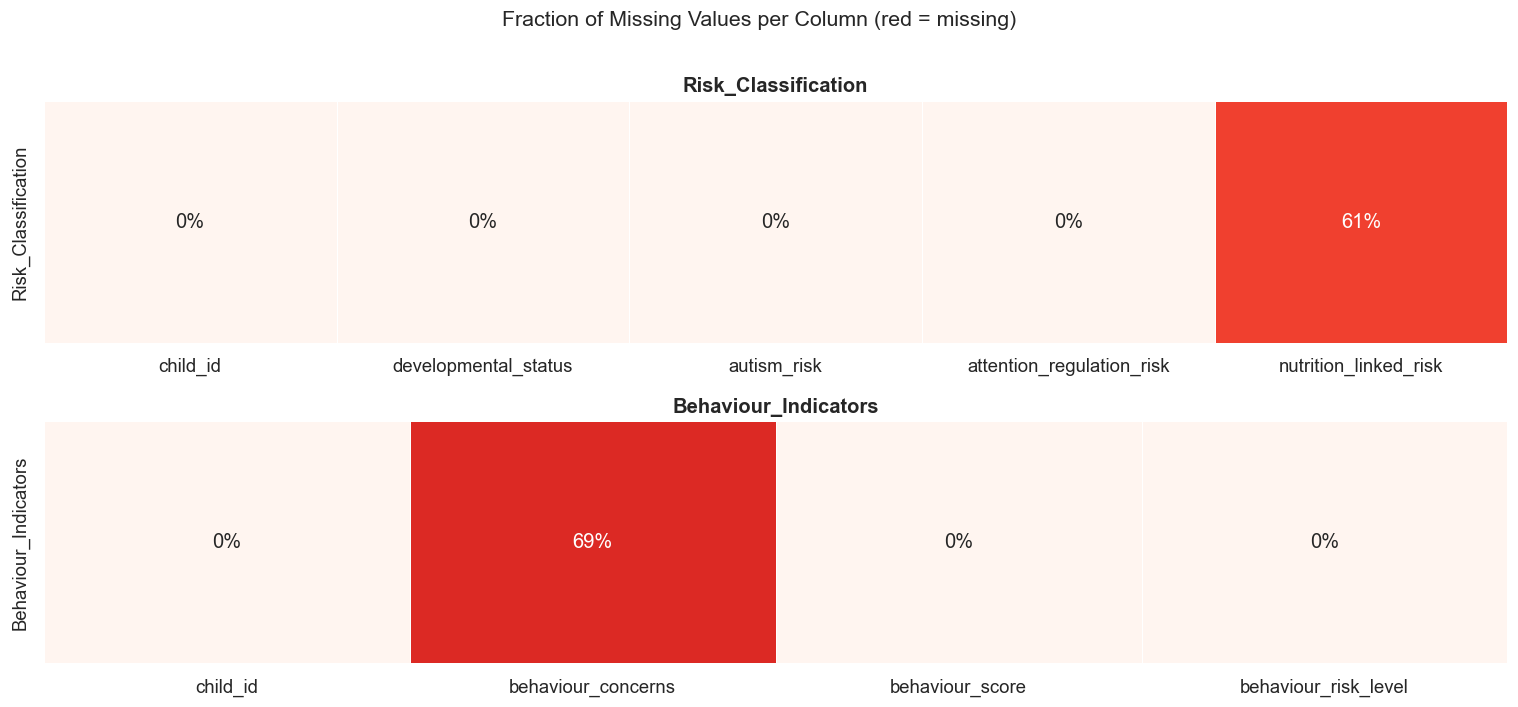

In [6]:
# Pre-filter to only sheets with missing data
sheets_with_missing = [
    sheet for sheet in DATA_SHEETS
    if all_sheets[sheet].isnull().any().any()
]

fig, axes = plt.subplots(len(sheets_with_missing), 1,
                         figsize=(14, 3.2 * len(sheets_with_missing)))

# Edge case: if only 1 sheet has missing data, axes won't be a list
if len(sheets_with_missing) == 1:
    axes = [axes]

for ax, sheet in zip(axes, sheets_with_missing):
    df = all_sheets[sheet]
    miss = df.isnull().mean().rename(sheet)
    sns.heatmap(miss.to_frame().T, ax=ax, cmap='Reds', vmin=0, vmax=1,
                annot=True, fmt='.0%', linewidths=.5, cbar=False)
    ax.set_title(sheet)
    ax.set_ylabel('')

fig.suptitle('Fraction of Missing Values per Column (red = missing)', y=1.005, fontsize=14)
plt.tight_layout()
plt.show()

## 2  Registration Sheet

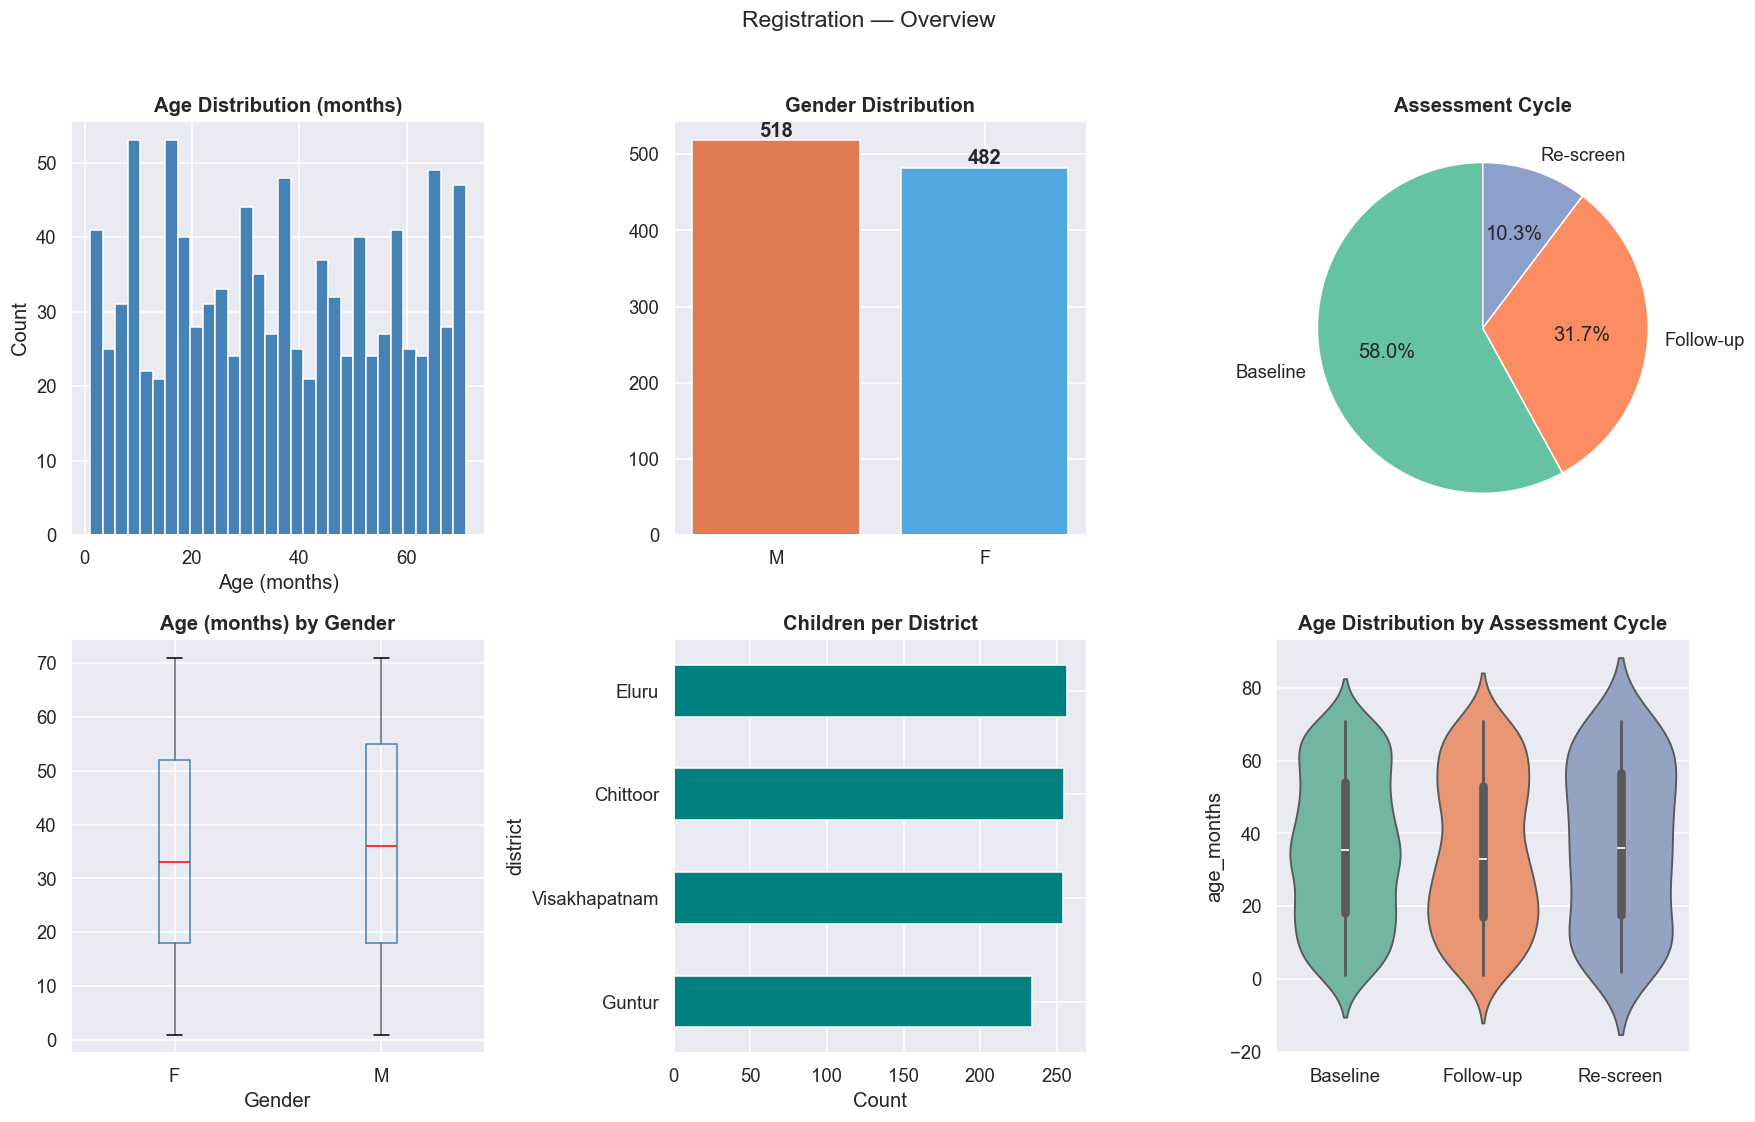

In [7]:
reg = all_sheets['Registration']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

# 2a  Age distribution
axes[0].hist(reg['age_months'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Age Distribution (months)')
axes[0].set_xlabel('Age (months)')
axes[0].set_ylabel('Count')

# 2b  Gender
vc = reg['gender'].value_counts()
axes[1].bar(vc.index, vc.values, color=['#E07B54','#54A8E0'], edgecolor='white')
axes[1].set_title('Gender Distribution')
for i, v in enumerate(vc.values):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

# 2c  Assessment cycle
vc2 = reg['assessment_cycle'].value_counts()
axes[2].pie(vc2, labels=vc2.index, autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette('Set2', len(vc2)))
axes[2].set_title('Assessment Cycle')

# 2d  Age box per gender
reg.boxplot(column='age_months', by='gender', ax=axes[3],
            boxprops=dict(color='steelblue'), medianprops=dict(color='red'))
axes[3].set_title('Age (months) by Gender')
axes[3].set_xlabel('Gender')
plt.sca(axes[3])
plt.suptitle('')

# 2e  Children per district
dist_count = reg['district'].value_counts()
dist_count.sort_values().plot(kind='barh', ax=axes[4], color='teal')
axes[4].set_title('Children per District')
axes[4].set_xlabel('Count')

# 2f  Age by assessment cycle violin
sns.violinplot(data=reg, x='assessment_cycle', y='age_months',
               palette='Set2', ax=axes[5], inner='box')
axes[5].set_title('Age Distribution by Assessment Cycle')
axes[5].set_xlabel('')

plt.suptitle('Registration — Overview', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()


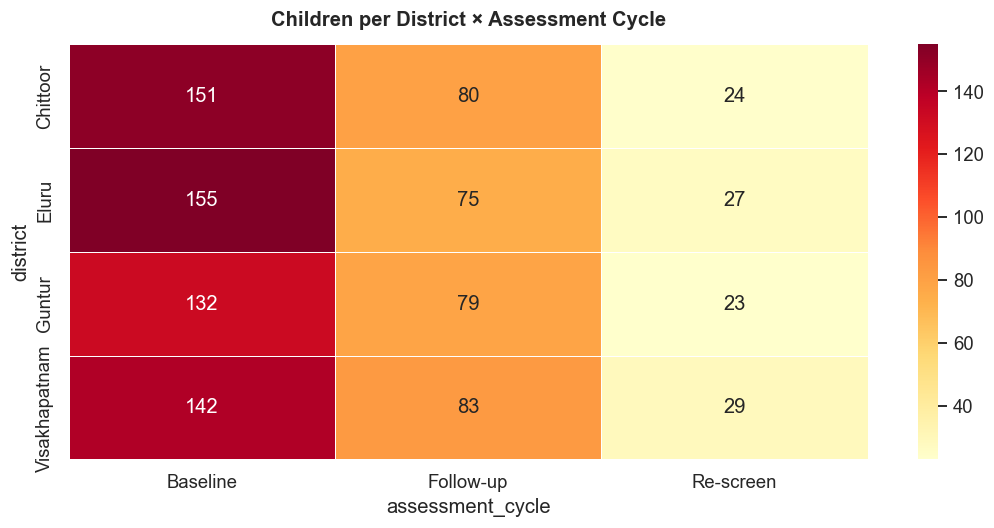

In [8]:
pivot = reg.groupby(['district','assessment_cycle']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlOrRd', linewidths=.5, ax=ax)
ax.set_title('Children per District × Assessment Cycle', pad=12)
plt.tight_layout()
plt.show()


## 3  Developmental Risk / Delays

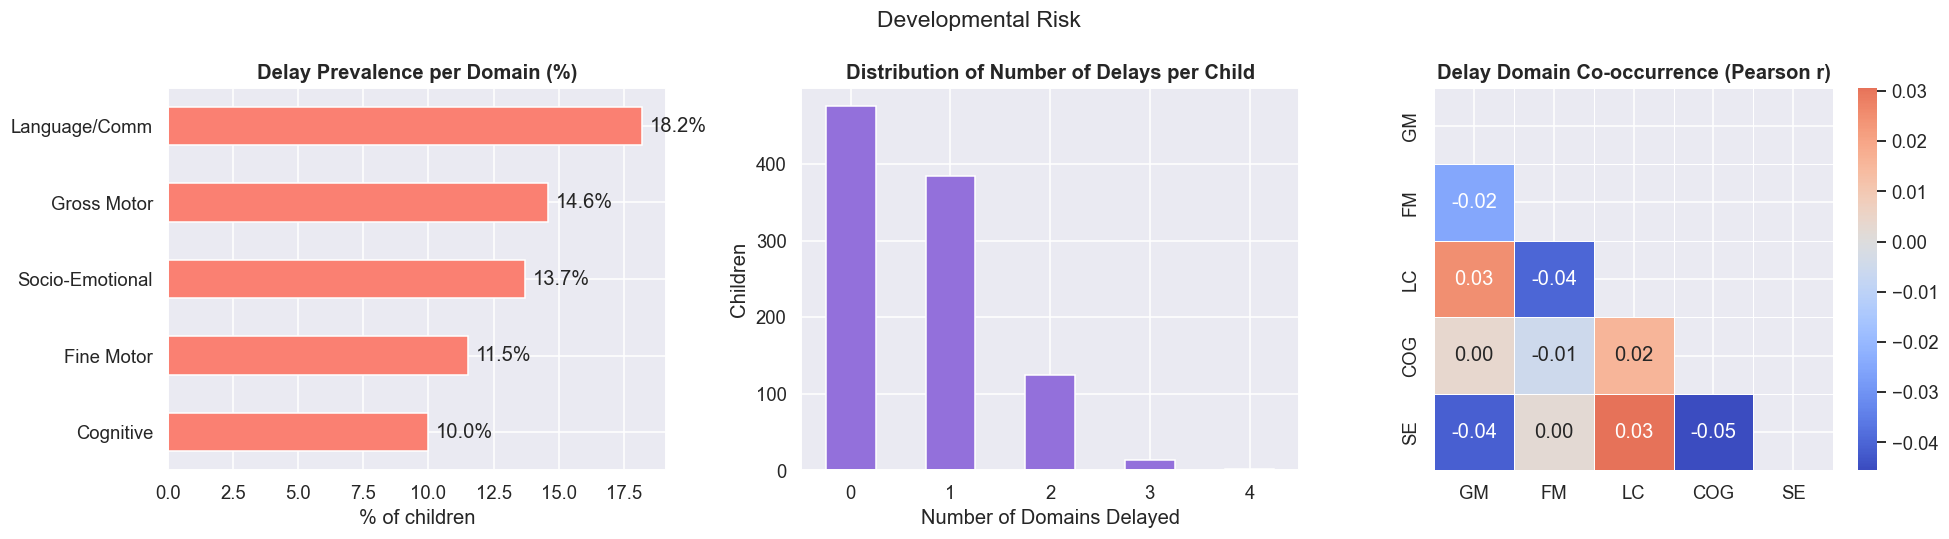

In [9]:
dev = all_sheets['Developmental_Risk']
delay_cols = ['GM_delay','FM_delay','LC_delay','COG_delay','SE_delay']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 3a  Delay prevalence per domain
rates = dev[delay_cols].mean() * 100
rates.index = ['Gross Motor','Fine Motor','Language/Comm','Cognitive','Socio-Emotional']
rates.sort_values().plot(kind='barh', ax=axes[0], color='salmon')
axes[0].set_title('Delay Prevalence per Domain (%)')
axes[0].set_xlabel('% of children')
for i, v in enumerate(rates.sort_values()):
    axes[0].text(v + 0.3, i, f'{v:.1f}%', va='center')

# 3b  Number of delays histogram
dev['num_delays'].value_counts().sort_index().plot(kind='bar', ax=axes[1],
    color='mediumpurple', edgecolor='white', rot=0)
axes[1].set_title('Distribution of Number of Delays per Child')
axes[1].set_xlabel('Number of Domains Delayed')
axes[1].set_ylabel('Children')

# 3c  Co-occurrence heatmap of delays
corr = dev[delay_cols].corr()
corr.index = corr.columns = ['GM','FM','LC','COG','SE']
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, ax=axes[2], mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=.5)
axes[2].set_title('Delay Domain Co-occurrence (Pearson r)')

plt.suptitle('Developmental Risk', fontsize=15)
plt.tight_layout()
plt.show()


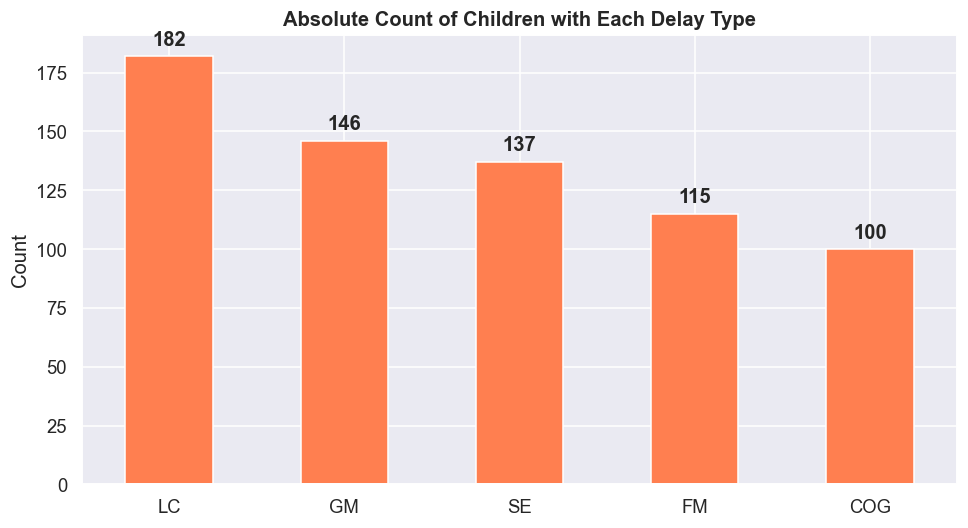

In [10]:
# 3d  Delay pairs stacked bars
fig, ax = plt.subplots(figsize=(9, 5))
delay_labels = ['GM','FM','LC','COG','SE']
delay_data = dev[delay_cols].copy()
delay_data.columns = delay_labels
total = delay_data.sum()
total.sort_values(ascending=False).plot(kind='bar', ax=ax, color='coral', edgecolor='white', rot=0)
ax.set_title('Absolute Count of Children with Each Delay Type')
ax.set_ylabel('Count')
for patch in ax.patches:
    ax.text(patch.get_x() + patch.get_width()/2, patch.get_height() + 3,
            int(patch.get_height()), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


## 4  Neuro-Behavioral Risks

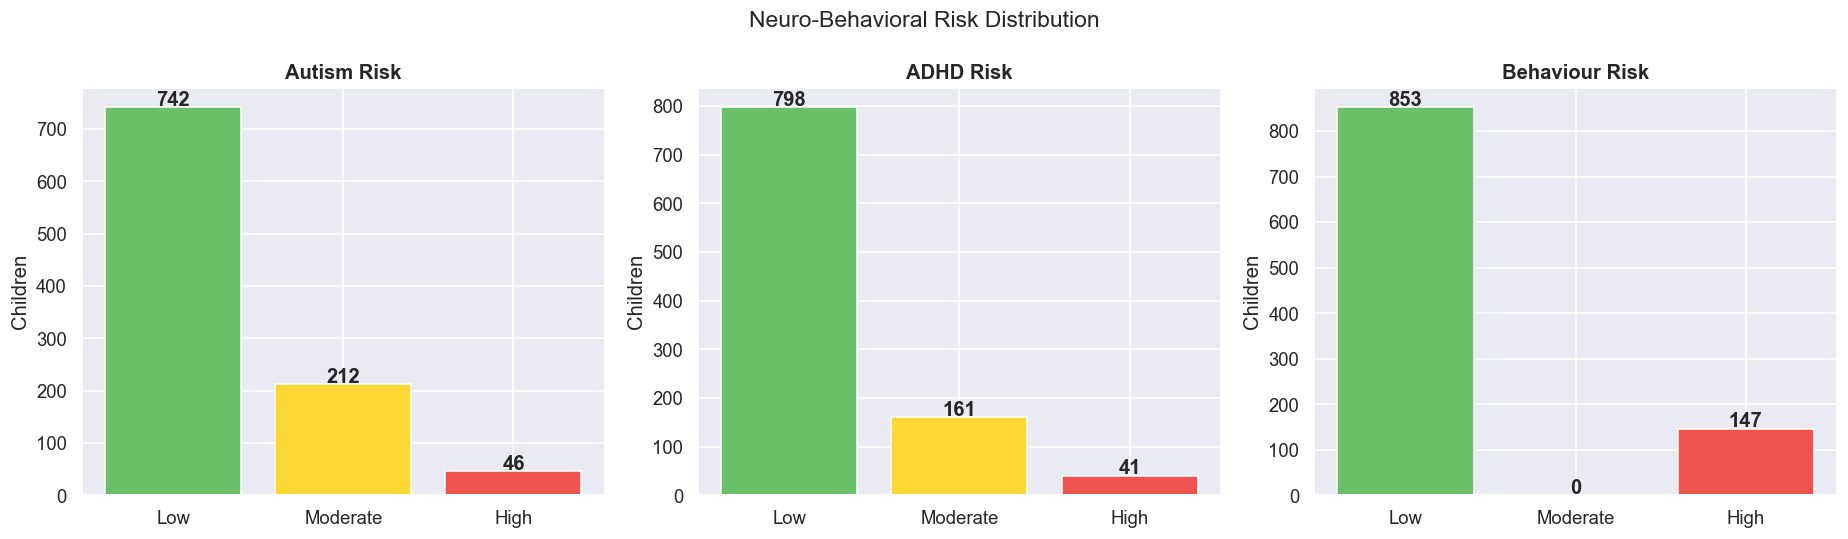

In [11]:
nb_df = all_sheets['Neuro_Behavioral']
risk_cols = ['autism_risk','adhd_risk','behavior_risk']
risk_labels = ['Autism Risk','ADHD Risk','Behaviour Risk']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, label in zip(axes, risk_cols, risk_labels):
    order = ['Low','Moderate','High']
    vc = nb_df[col].value_counts().reindex(order, fill_value=0)
    bars = ax.bar(vc.index, vc.values,
                  color=['#6abf69','#fdd835','#ef5350'], edgecolor='white')
    ax.set_title(label)
    ax.set_ylabel('Children')
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 3,
                int(b.get_height()), ha='center', fontweight='bold')

plt.suptitle('Neuro-Behavioral Risk Distribution', fontsize=15)
plt.tight_layout()
plt.show()


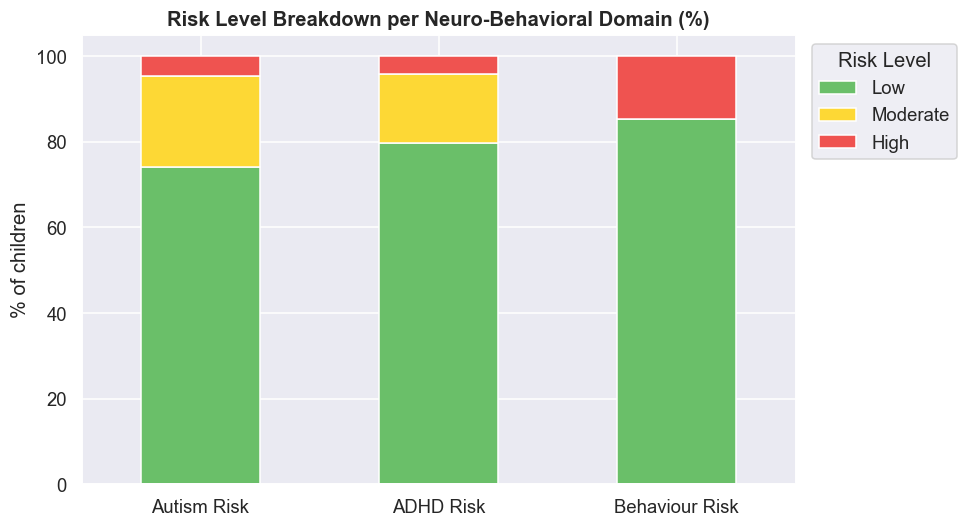

In [12]:
# 4b  Stacked 100 % bar — risk profile comparison
order = ['Low','Moderate','High']
pct_df = pd.DataFrame({
    col: nb_df[col].value_counts(normalize=True).reindex(order, fill_value=0)*100
    for col in risk_cols
}).T
pct_df.index = risk_labels

pct_df.plot(kind='bar', stacked=True, figsize=(9, 5),
            color=['#6abf69','#fdd835','#ef5350'], edgecolor='white', rot=0)
plt.title('Risk Level Breakdown per Neuro-Behavioral Domain (%)')
plt.ylabel('% of children')
plt.legend(title='Risk Level', bbox_to_anchor=(1.01,1), loc='upper left')
plt.tight_layout()
plt.show()


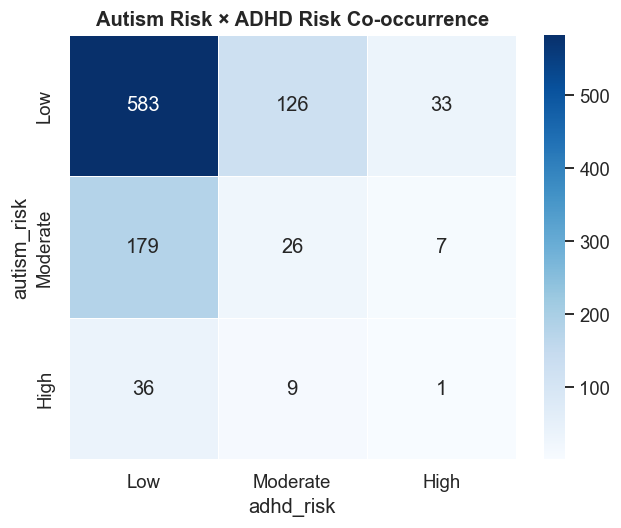

In [13]:
# 4c  Cross-tab heatmap autism × adhd
ct = pd.crosstab(nb_df['autism_risk'], nb_df['adhd_risk'])
ct = ct.reindex(index=['Low','Moderate','High'], columns=['Low','Moderate','High'], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', linewidths=.5, ax=ax)
ax.set_title('Autism Risk × ADHD Risk Co-occurrence')
plt.tight_layout()
plt.show()


## 5  Nutrition

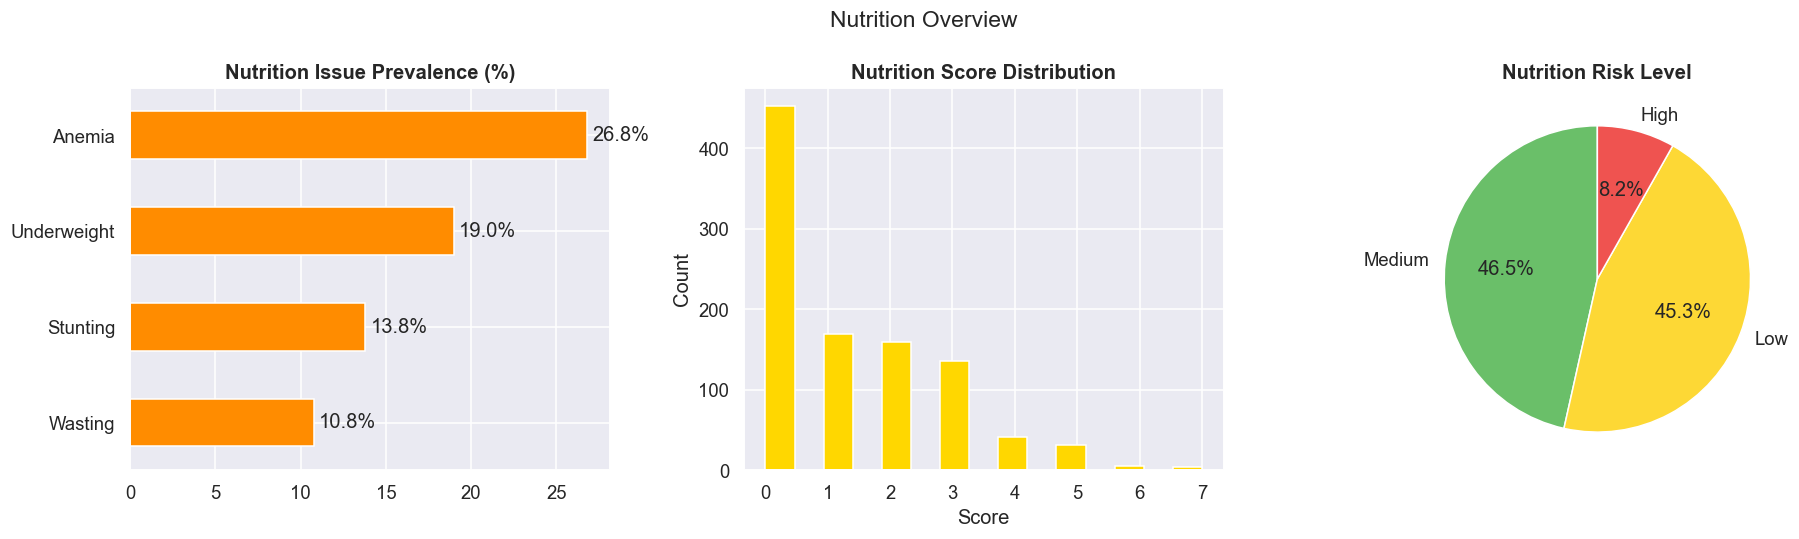

In [14]:
nut = all_sheets['Nutrition']
nut_bin_cols = ['underweight','stunting','wasting','anemia']
nut_labels   = ['Underweight','Stunting','Wasting','Anemia']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 5a  Prevalence per indicator
rates = nut[nut_bin_cols].mean()*100
rates.index = nut_labels
rates.sort_values().plot(kind='barh', ax=axes[0], color='darkorange')
axes[0].set_title('Nutrition Issue Prevalence (%)')
for i, v in enumerate(rates.sort_values()):
    axes[0].text(v+0.3, i, f'{v:.1f}%', va='center')

# 5b  Nutrition score distribution
axes[1].hist(nut['nutrition_score'], bins=15, color='gold', edgecolor='white')
axes[1].set_title('Nutrition Score Distribution')
axes[1].set_xlabel('Score')
axes[1].set_ylabel('Count')

# 5c  Nutrition risk pie
vc = nut['nutrition_risk'].value_counts()
axes[2].pie(vc, labels=vc.index, autopct='%1.1f%%',
            colors=['#6abf69','#fdd835','#ef5350'][:len(vc)], startangle=90)
axes[2].set_title('Nutrition Risk Level')

plt.suptitle('Nutrition Overview', fontsize=15)
plt.tight_layout()
plt.show()


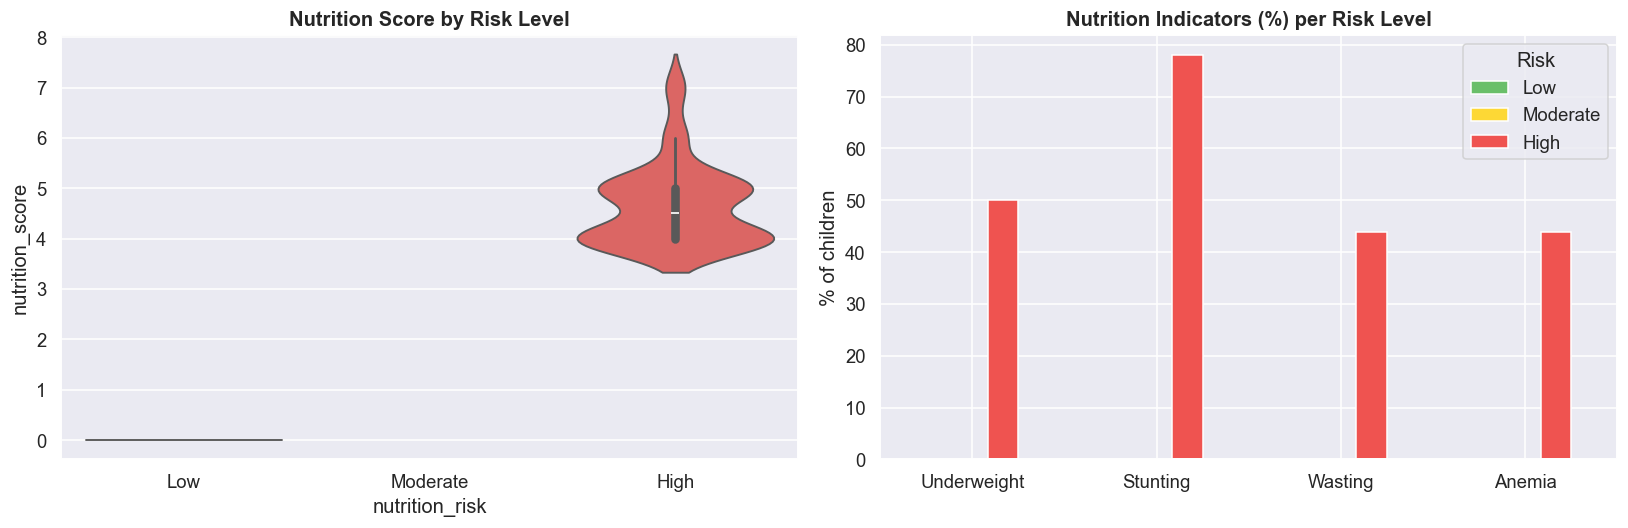

In [15]:
# 5d  Score by risk level (violin) + individual indicators by risk (grouped bars)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order_risk = ['Low','Moderate','High']
sns.violinplot(data=nut, x='nutrition_risk', y='nutrition_score',
               order=order_risk, palette=['#6abf69','#fdd835','#ef5350'],
               inner='box', ax=axes[0])
axes[0].set_title('Nutrition Score by Risk Level')

pct = nut.groupby('nutrition_risk')[nut_bin_cols].mean()*100
pct.index.name = 'Risk'
pct.columns = nut_labels
pct = pct.reindex(order_risk)
pct.T.plot(kind='bar', ax=axes[1], color=['#6abf69','#fdd835','#ef5350'], edgecolor='white', rot=0)
axes[1].set_title('Nutrition Indicators (%) per Risk Level')
axes[1].set_ylabel('% of children')
axes[1].legend(title='Risk')

plt.tight_layout()
plt.show()


## 6  Environment & Caregiving

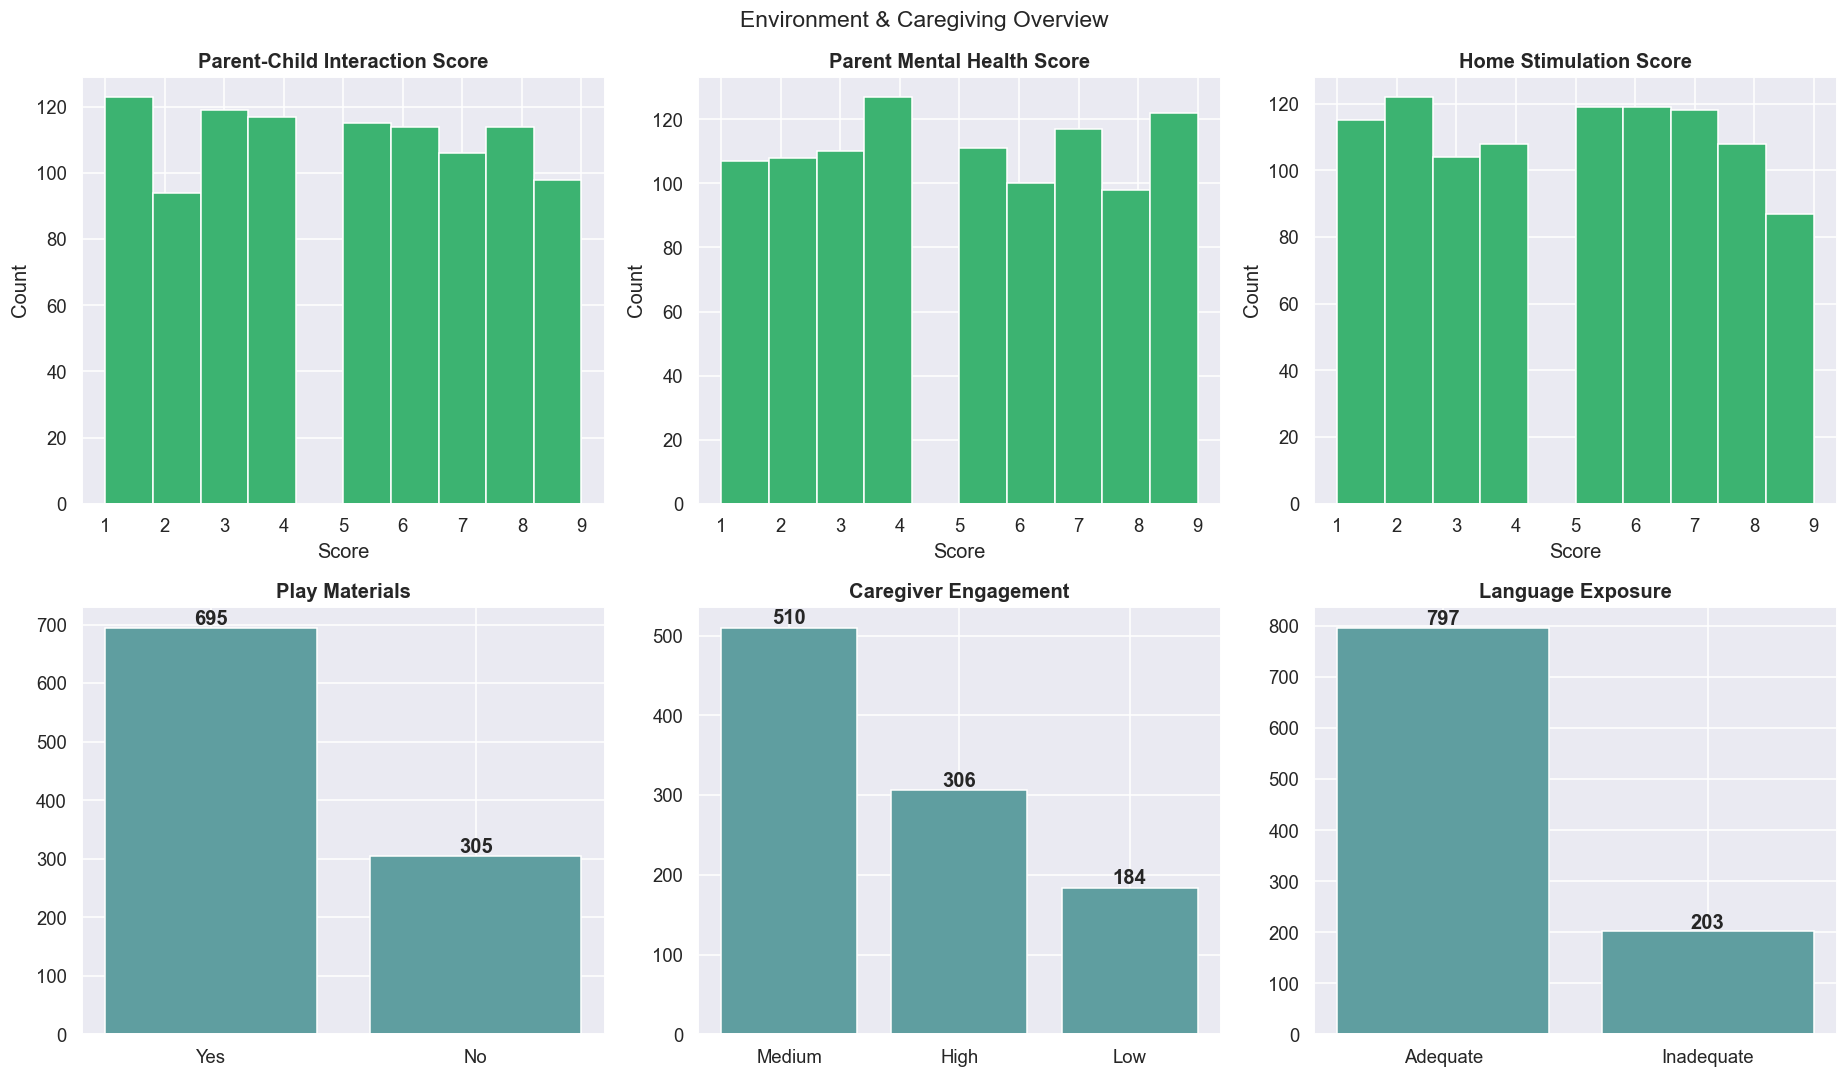

In [16]:
env = all_sheets['Environment_Caregiving']
score_cols = ['parent_child_interaction_score','parent_mental_health_score','home_stimulation_score']
score_labels = ['Parent-Child Interaction','Parent Mental Health','Home Stimulation']
cat_cols_env = ['play_materials','caregiver_engagement','language_exposure','safe_water','toilet_facility']

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()

# 6a-6c  Score histograms
for ax, col, lbl in zip(axes[:3], score_cols, score_labels):
    ax.hist(env[col], bins=10, color='mediumseagreen', edgecolor='white')
    ax.set_title(f'{lbl} Score')
    ax.set_xlabel('Score')
    ax.set_ylabel('Count')

# 6d-6f  Categorical bars
for ax, col in zip(axes[3:6], cat_cols_env[:3]):
    vc = env[col].value_counts()
    ax.bar(vc.index, vc.values, color='cadetblue', edgecolor='white')
    ax.set_title(col.replace('_',' ').title())
    for i, v in enumerate(vc.values):
        ax.text(i, v+5, str(v), ha='center', fontweight='bold')

plt.suptitle('Environment & Caregiving Overview', fontsize=15)
plt.tight_layout()
plt.show()


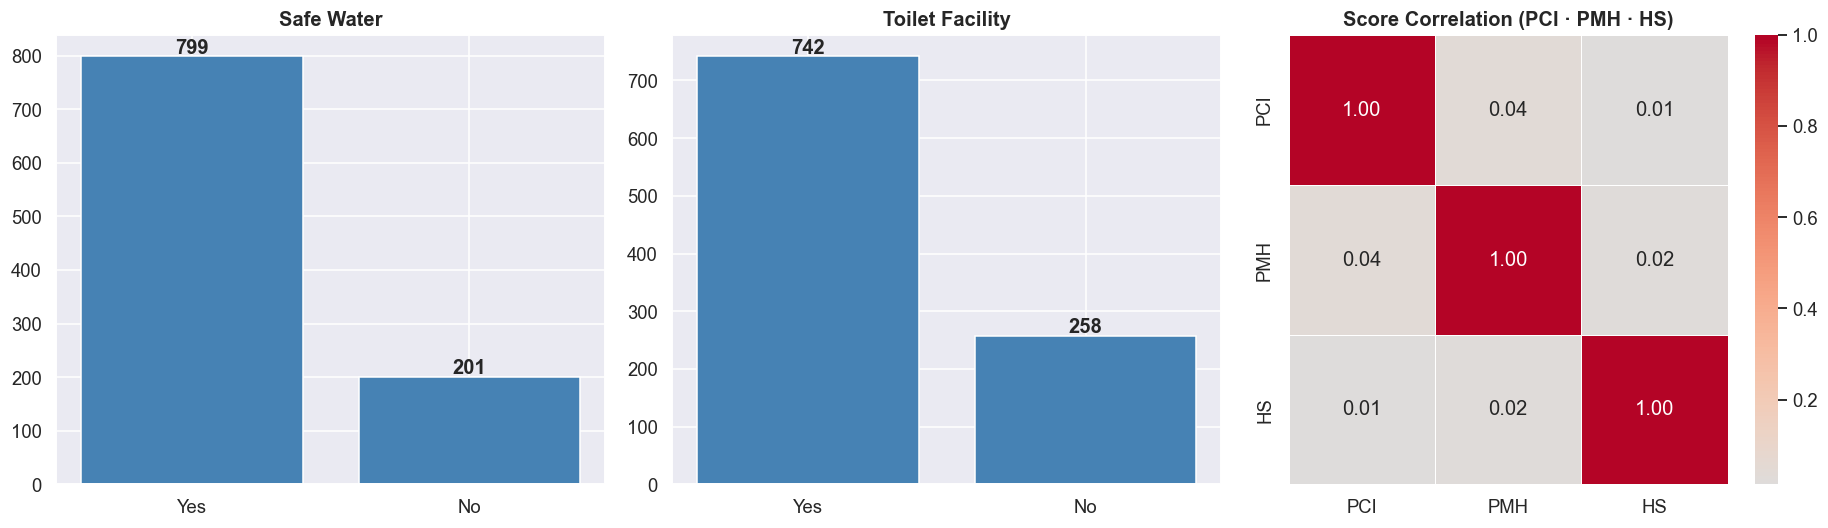

In [17]:
# 6d  Remaining categorical + score correlation
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, col in zip(axes[:2], cat_cols_env[3:]):
    vc = env[col].value_counts()
    ax.bar(vc.index, vc.values, color='steelblue', edgecolor='white')
    ax.set_title(col.replace('_',' ').title())
    for i, v in enumerate(vc.values):
        ax.text(i, v+5, str(v), ha='center', fontweight='bold')

# Score pairplot-style scatter matrix
score_df = env[score_cols].copy()
score_df.columns = ['PCI','PMH','HS']
corr_env = score_df.corr()
sns.heatmap(corr_env, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=.5, ax=axes[2])
axes[2].set_title('Score Correlation (PCI · PMH · HS)')

plt.tight_layout()
plt.show()


## 7  Developmental Assessment (DQ Scores)

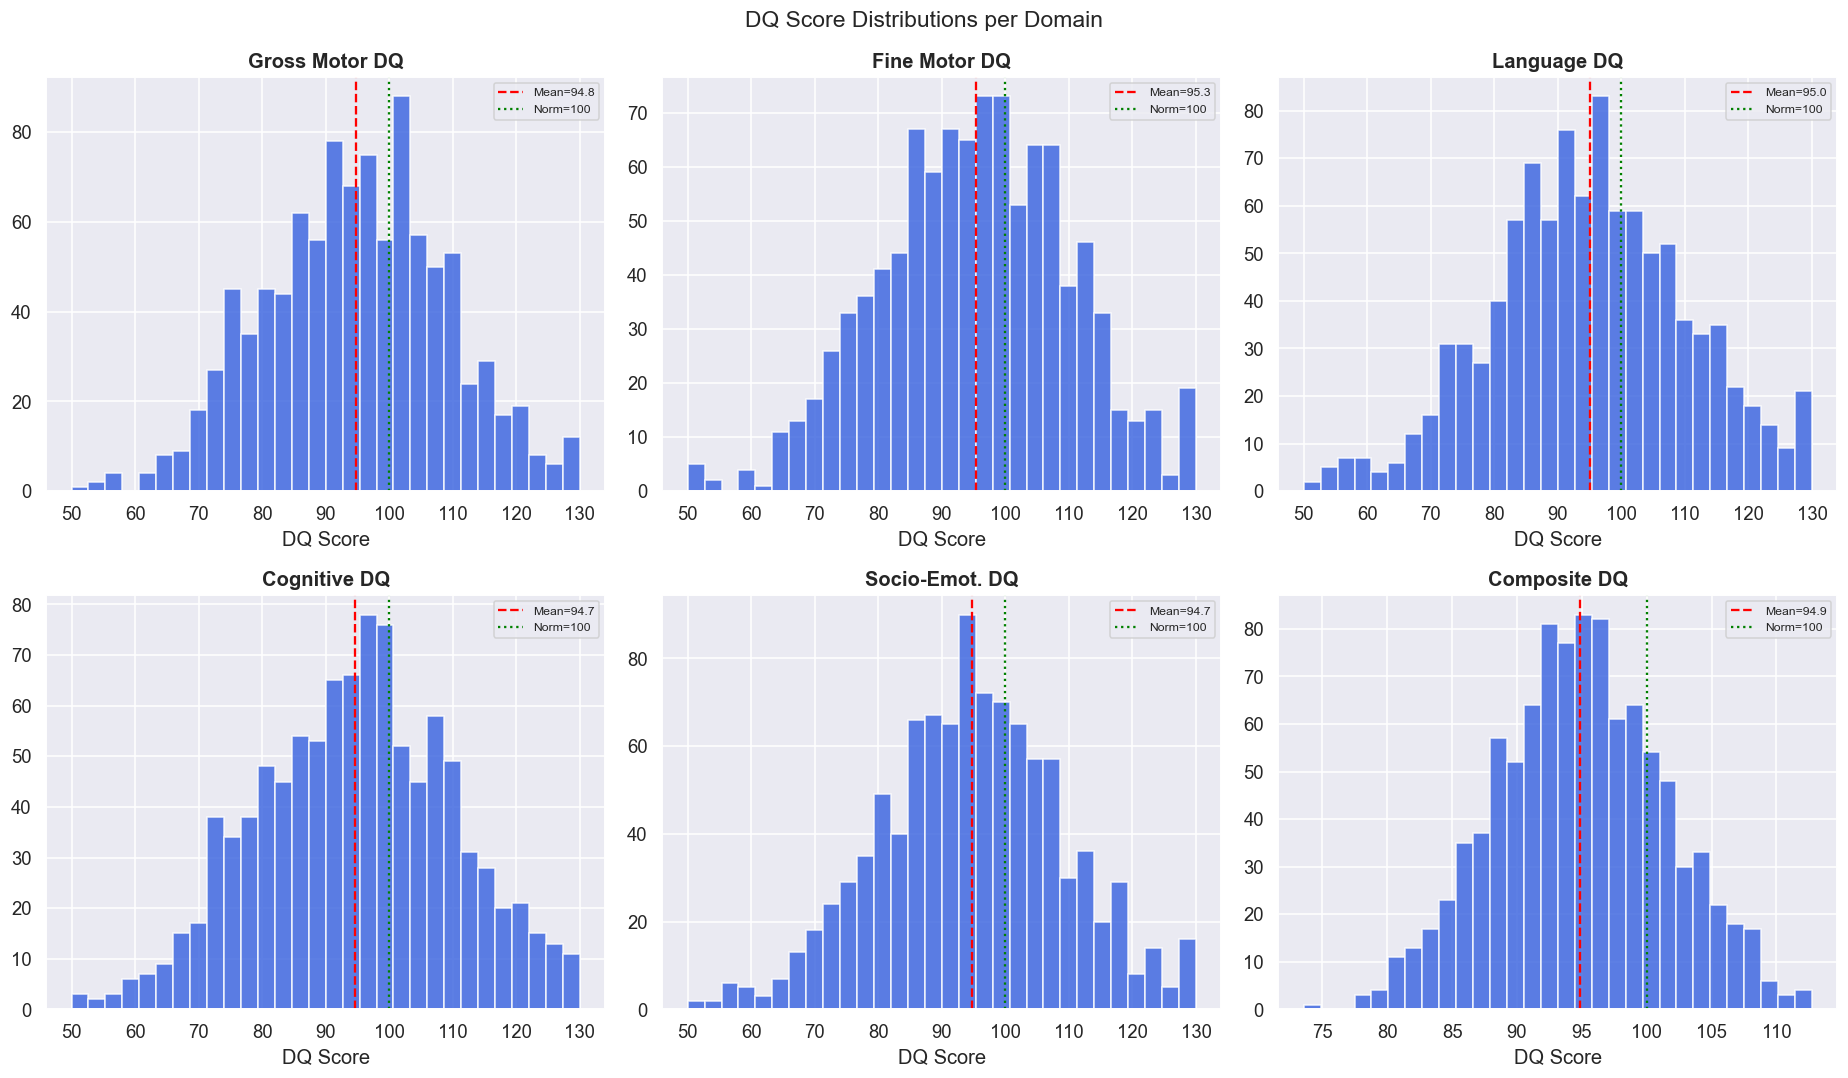

In [18]:
da = all_sheets['Developmental_Assessment']
dq_cols = ['GM_DQ','FM_DQ','LC_DQ','COG_DQ','SE_DQ','Composite_DQ']
dq_labels = ['Gross Motor','Fine Motor','Language','Cognitive','Socio-Emot.','Composite']

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()
for ax, col, lbl in zip(axes, dq_cols, dq_labels):
    ax.hist(da[col], bins=30, color='royalblue', edgecolor='white', alpha=0.85)
    ax.axvline(da[col].mean(), color='red', linestyle='--', label=f'Mean={da[col].mean():.1f}')
    ax.axvline(100, color='green', linestyle=':', label='Norm=100')
    ax.set_title(f'{lbl} DQ')
    ax.set_xlabel('DQ Score')
    ax.legend(fontsize=8)

plt.suptitle('DQ Score Distributions per Domain', fontsize=15)
plt.tight_layout()
plt.show()


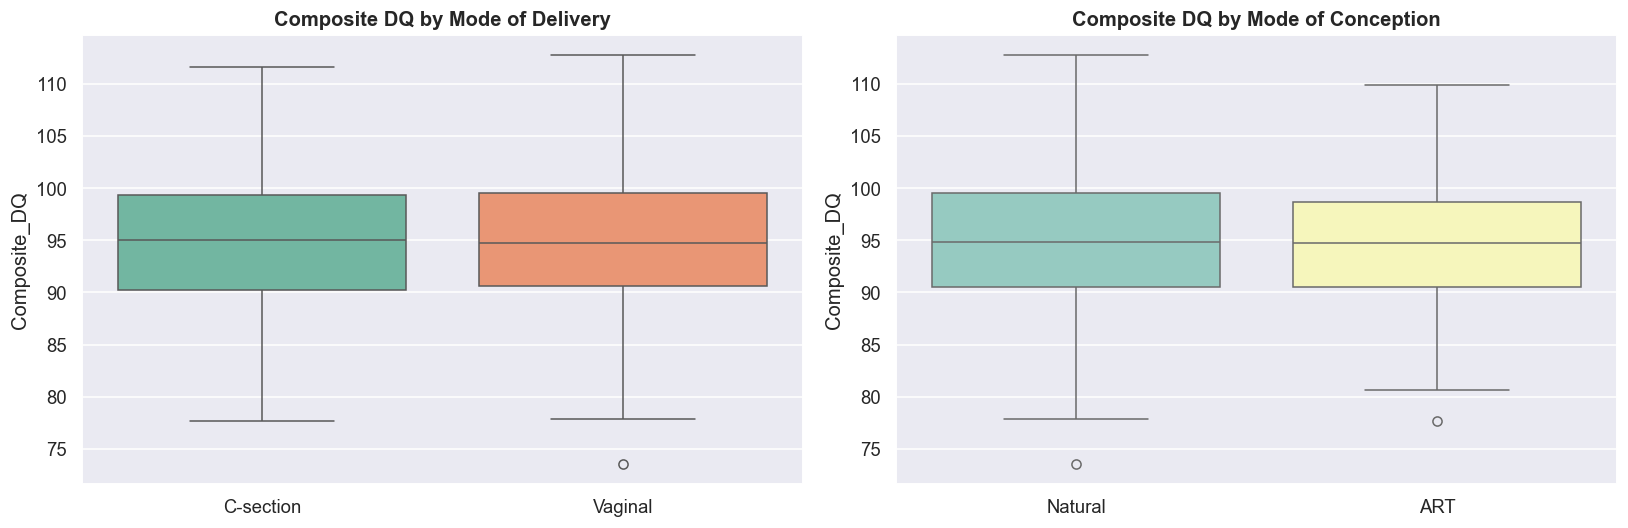

In [19]:
# 7b  Boxplots by mode of delivery & conception
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=da, x='mode_delivery', y='Composite_DQ',
            palette='Set2', ax=axes[0])
axes[0].set_title('Composite DQ by Mode of Delivery')
axes[0].set_xlabel('')

sns.boxplot(data=da, x='mode_conception', y='Composite_DQ',
            palette='Set3', ax=axes[1])
axes[1].set_title('Composite DQ by Mode of Conception')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()


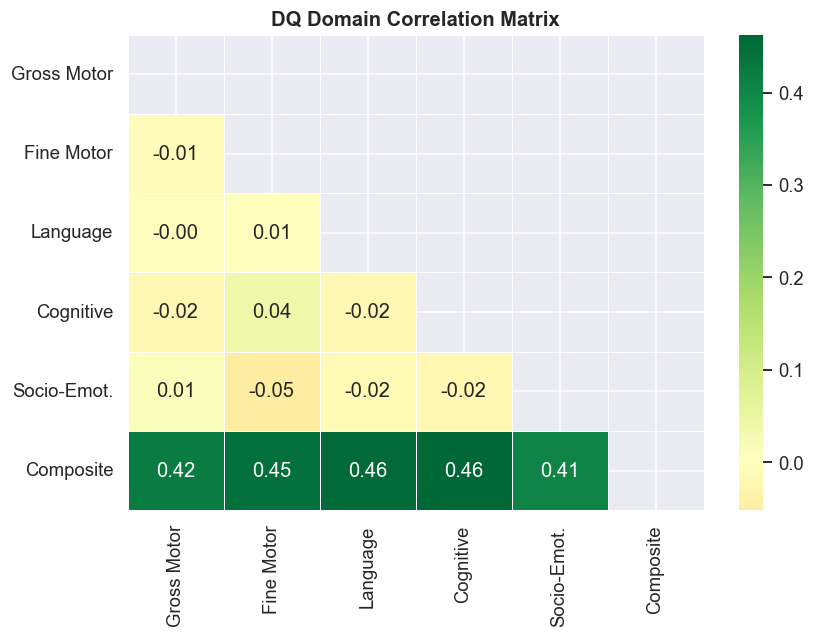

In [20]:
# 7c  DQ domain correlation heatmap
corr_dq = da[dq_cols].corr()
corr_dq.index = corr_dq.columns = dq_labels
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_dq, dtype=bool))
sns.heatmap(corr_dq, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=.5, ax=ax)
ax.set_title('DQ Domain Correlation Matrix')
plt.tight_layout()
plt.show()


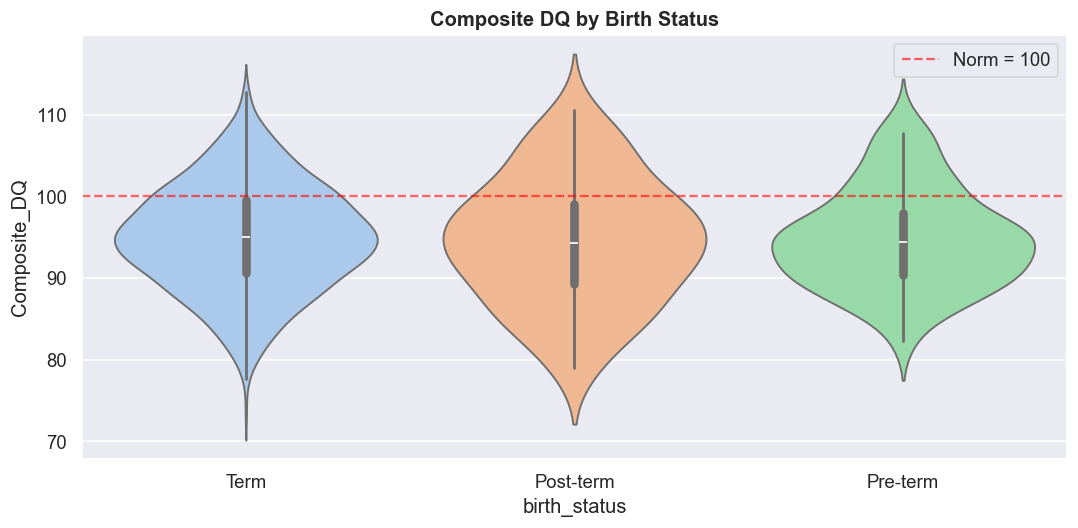

In [21]:
# 7d  Violin DQ by birth status
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=da, x='birth_status', y='Composite_DQ',
               palette='pastel', inner='box', ax=ax)
ax.axhline(100, color='red', linestyle='--', alpha=0.6, label='Norm = 100')
ax.set_title('Composite DQ by Birth Status')
ax.legend()
plt.tight_layout()
plt.show()


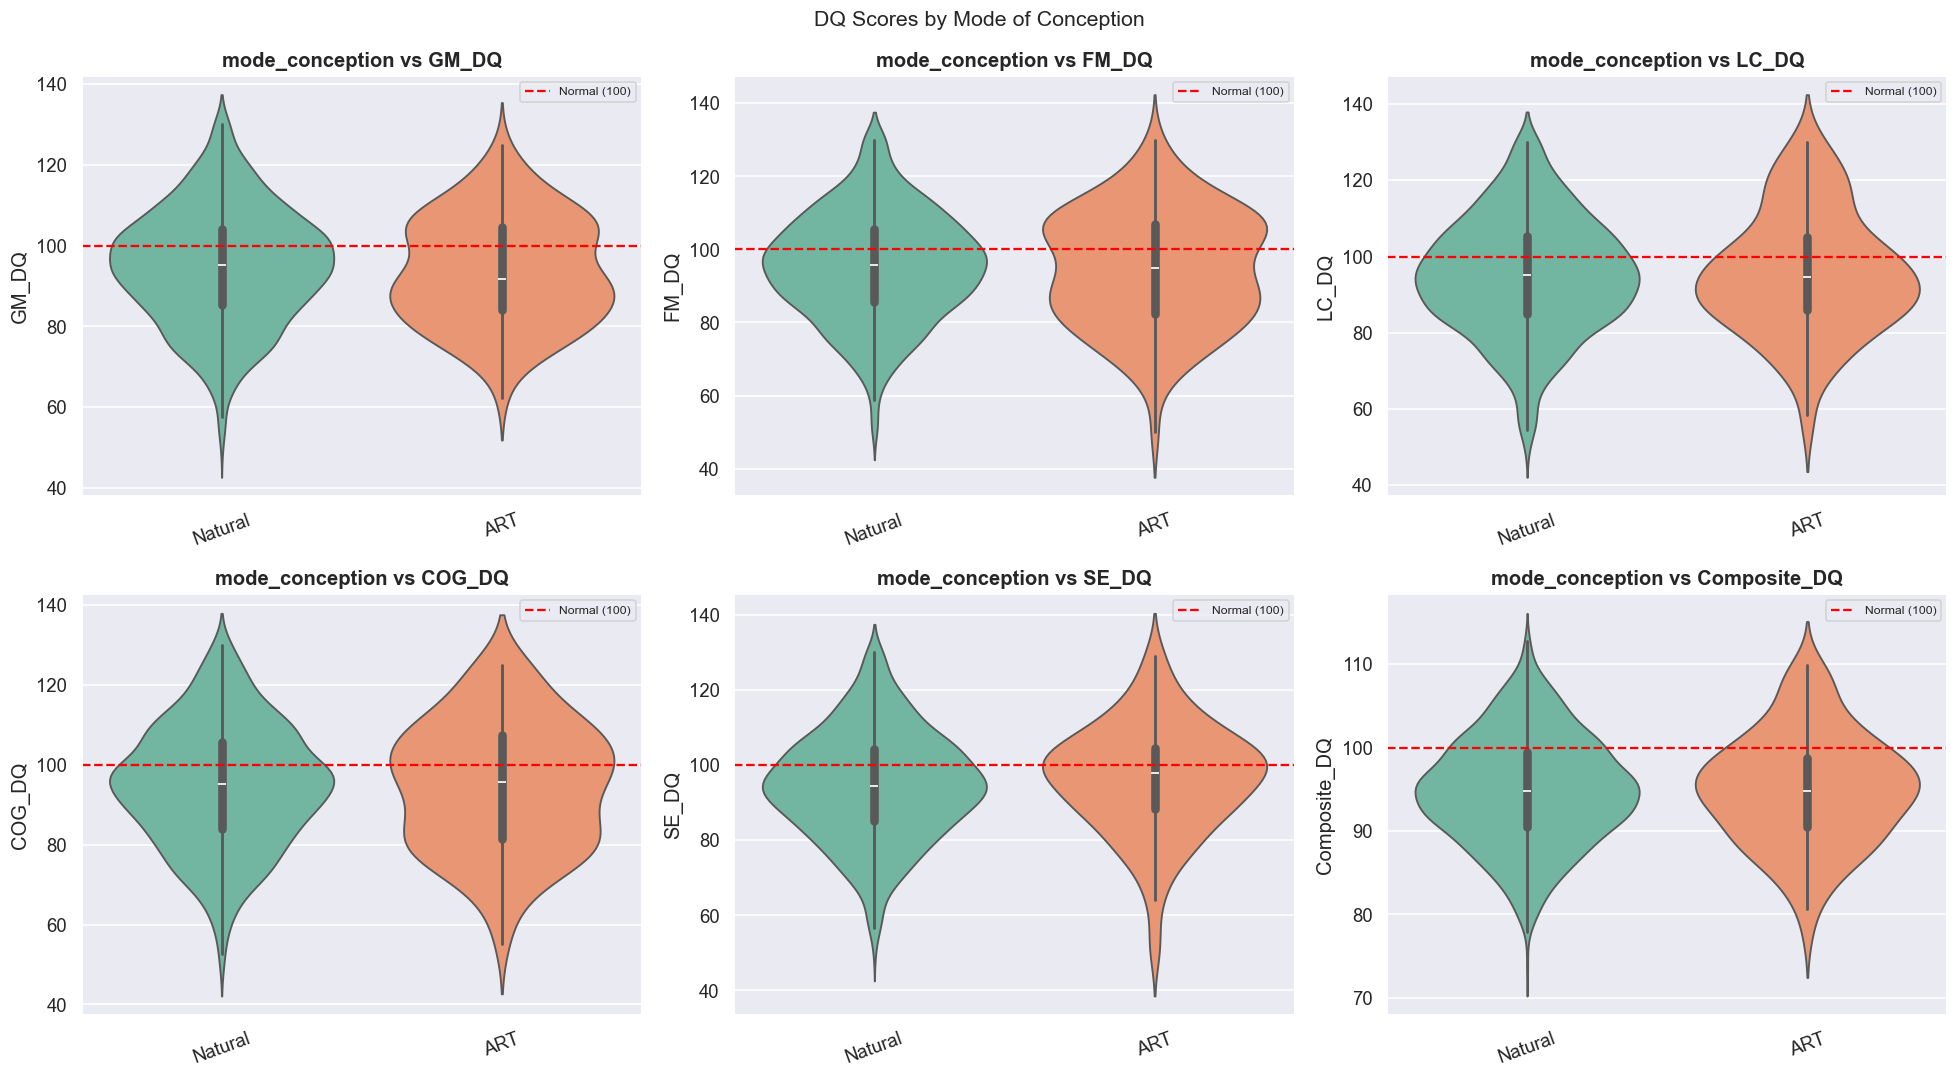

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

dq_cols = ['GM_DQ','FM_DQ','LC_DQ','COG_DQ','SE_DQ','Composite_DQ']

for ax, dq in zip(axes, dq_cols):
    sns.violinplot(data=da, x='mode_conception', y=dq,
                   palette='Set2', inner='box', ax=ax)
    ax.axhline(y=100, color='red', linestyle='--', linewidth=1.5, label='Normal (100)')
    ax.set_title(f'mode_conception vs {dq}')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
    ax.legend(fontsize=8)

plt.suptitle('DQ Scores by Mode of Conception', fontsize=14)
plt.tight_layout()
plt.show()

## 8  Risk Classification

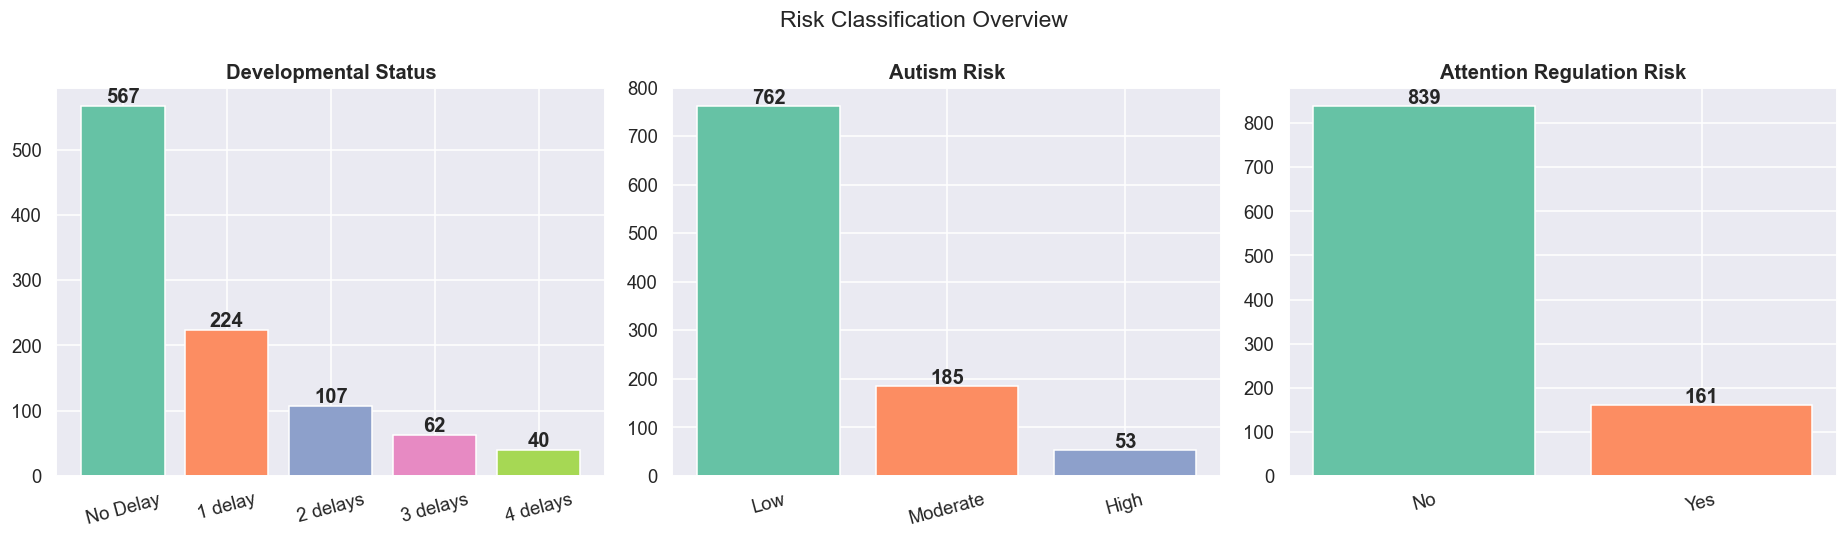

In [23]:
rc = all_sheets['Risk_Classification']
risk_cat_cols = ['developmental_status','autism_risk','attention_regulation_risk']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, risk_cat_cols):
    vc = rc[col].value_counts()
    colors = sns.color_palette('Set2', len(vc))
    ax.bar(vc.index, vc.values, color=colors, edgecolor='white')
    ax.set_title(col.replace('_',' ').title())
    for i, v in enumerate(vc.values):
        ax.text(i, v+5, str(v), ha='center', fontweight='bold')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Risk Classification Overview', fontsize=15)
plt.tight_layout()
plt.show()


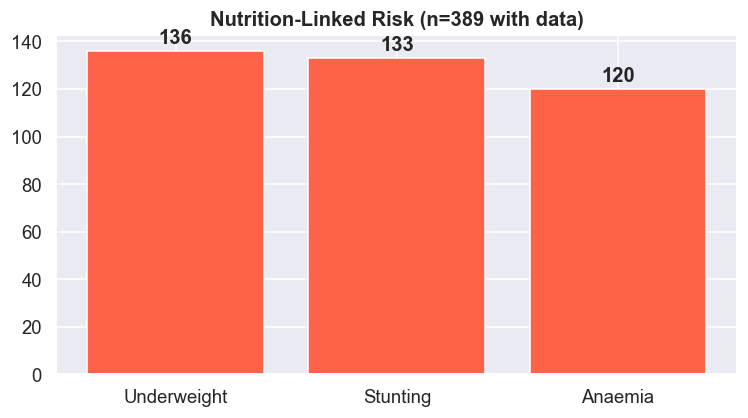

In [24]:
# 8b  Nutrition linked risk (non-null)
nut_risk_nn = rc['nutrition_linked_risk'].dropna()
vc = nut_risk_nn.value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(vc.index, vc.values, color='tomato', edgecolor='white')
ax.set_title(f'Nutrition-Linked Risk (n={len(nut_risk_nn)} with data)')
for i, v in enumerate(vc.values):
    ax.text(i, v+3, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


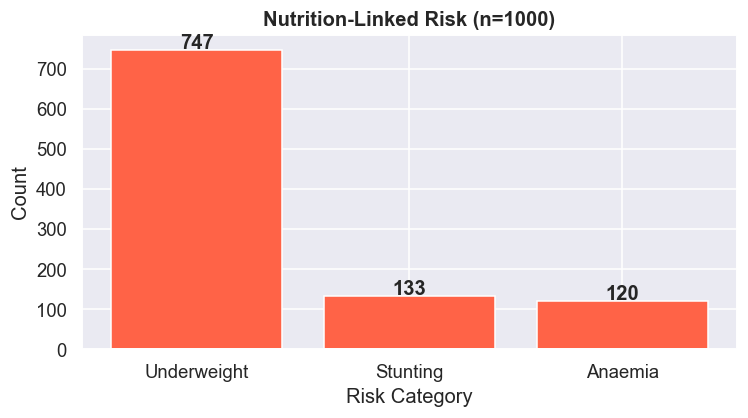

In [25]:
# Fill categorical columns with mode
cat_cols = rc.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    rc[col] = rc[col].fillna(rc[col].mode()[0])

# Now plot nutrition_linked_risk (after filling)
vc = rc['nutrition_linked_risk'].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(vc.index, vc.values, color='tomato', edgecolor='white')

ax.set_title(f'Nutrition-Linked Risk (n={len(rc)})')
ax.set_ylabel('Count')
ax.set_xlabel('Risk Category')

# Add value labels
for i, v in enumerate(vc.values):
    ax.text(i, v + 3, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 9  Behaviour Indicators

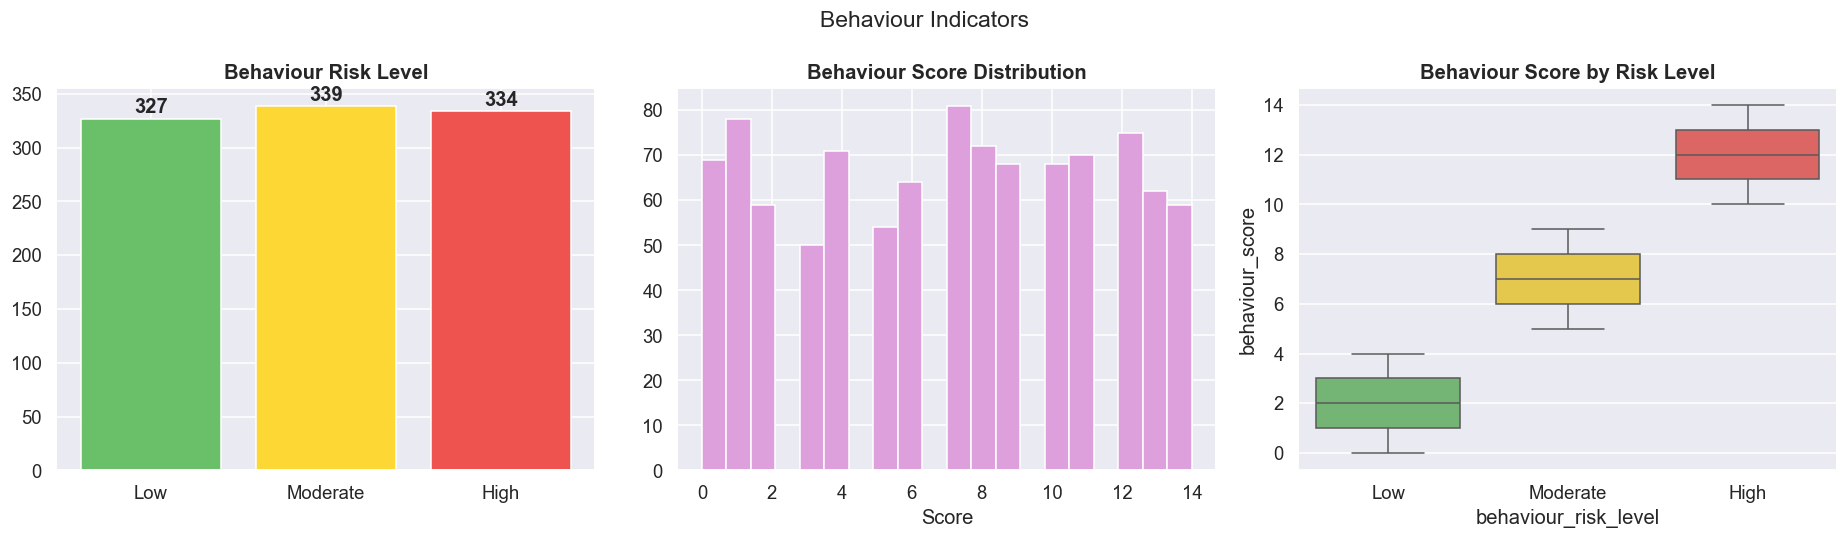

In [26]:
beh = all_sheets['Behaviour_Indicators']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 9a  Behaviour risk level
vc = beh['behaviour_risk_level'].value_counts()
order_risk = ['Low','Moderate','High']
vc = vc.reindex(order_risk, fill_value=0)
axes[0].bar(vc.index, vc.values,
            color=['#6abf69','#fdd835','#ef5350'], edgecolor='white')
axes[0].set_title('Behaviour Risk Level')
for i, v in enumerate(vc.values):
    axes[0].text(i, v+5, str(v), ha='center', fontweight='bold')

# 9b  Behaviour score histogram
axes[1].hist(beh['behaviour_score'], bins=20, color='plum', edgecolor='white')
axes[1].set_title('Behaviour Score Distribution')
axes[1].set_xlabel('Score')

# 9c  Score by risk level box
sns.boxplot(data=beh, x='behaviour_risk_level', y='behaviour_score',
            order=order_risk, palette=['#6abf69','#fdd835','#ef5350'], ax=axes[2])
axes[2].set_title('Behaviour Score by Risk Level')

plt.suptitle('Behaviour Indicators', fontsize=15)
plt.tight_layout()
plt.show()


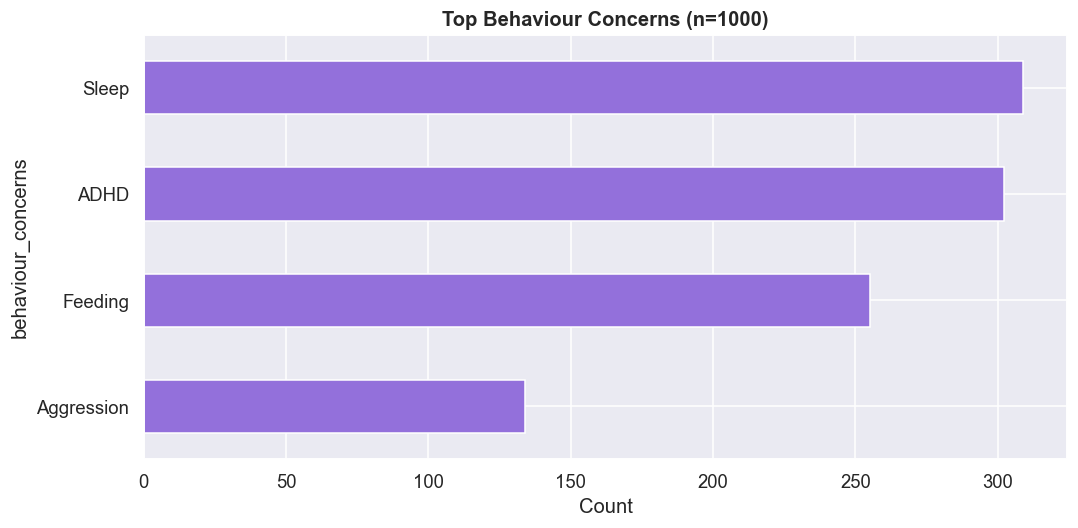

In [27]:
# Make a copy to avoid modifying original
beh_copy = beh.copy()

col = 'behaviour_concerns'

# Get distribution of existing (non-null) categories
probs = beh_copy[col].value_counts(normalize=True)

# Randomly fill missing values based on observed probabilities
beh_copy[col] = beh_copy[col].apply(
    lambda x: np.random.choice(probs.index, p=probs.values) if pd.isna(x) else x
)

# Value counts (top 10)
vc_c = beh_copy[col].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))

vc_c.sort_values().plot(
    kind='barh',
    ax=ax,
    color='mediumpurple',
    edgecolor='white'
)

ax.set_title(f'Top Behaviour Concerns (n={len(beh_copy)})')
ax.set_xlabel('Count')

plt.tight_layout()
plt.show()

## 10  Baseline Risk Output

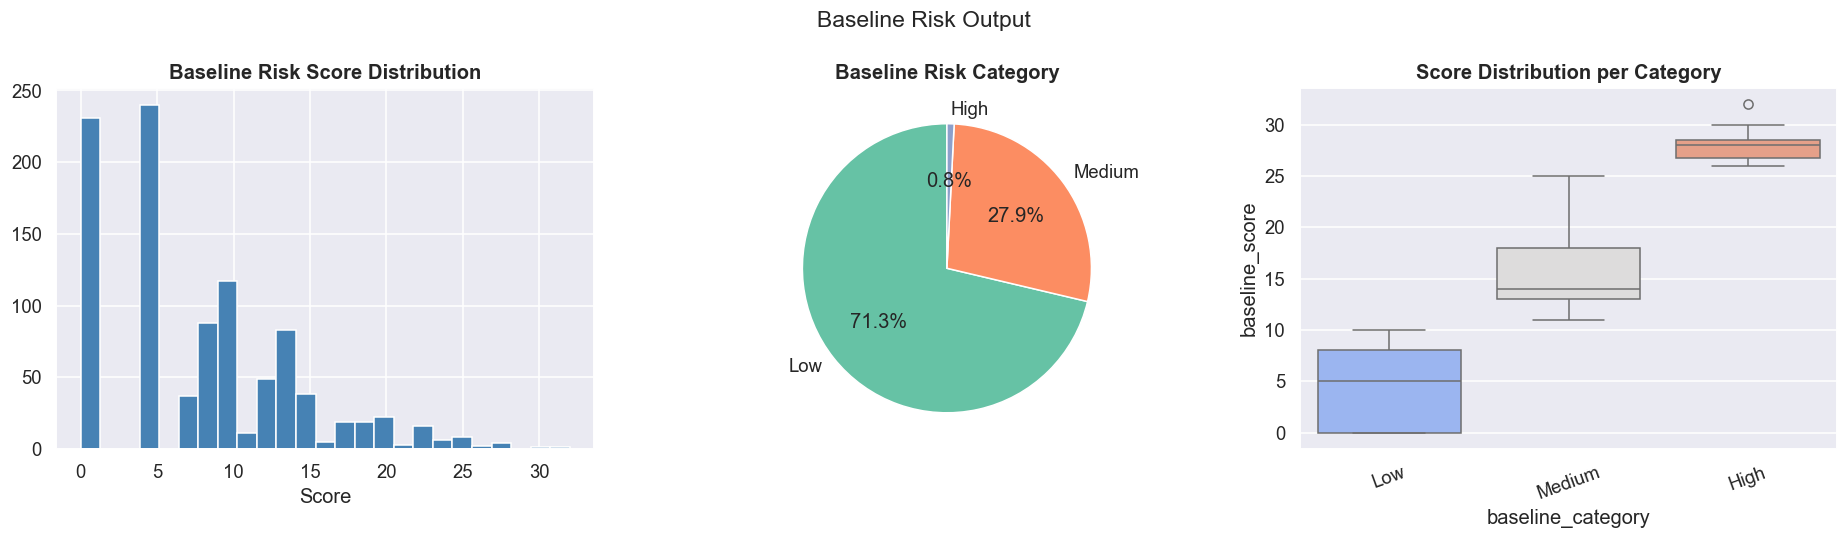

In [28]:
bro = all_sheets['Baseline_Risk_Output'][['child_id','baseline_score','baseline_category']]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 10a  Score distribution
axes[0].hist(bro['baseline_score'], bins=25, color='steelblue', edgecolor='white')
axes[0].set_title('Baseline Risk Score Distribution')
axes[0].set_xlabel('Score')

# 10b  Category pie
vc = bro['baseline_category'].value_counts()
axes[1].pie(vc, labels=vc.index, autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette('Set2', len(vc)))
axes[1].set_title('Baseline Risk Category')

# 10c  Box per category
order_cat = bro.groupby('baseline_category')['baseline_score'].median().sort_values().index.tolist()
sns.boxplot(data=bro, x='baseline_category', y='baseline_score',
            order=order_cat, palette='coolwarm', ax=axes[2])
axes[2].set_title('Score Distribution per Category')
axes[2].tick_params(axis='x', rotation=20)

plt.suptitle('Baseline Risk Output', fontsize=15)
plt.tight_layout()
plt.show()


## 11  Referral Actions

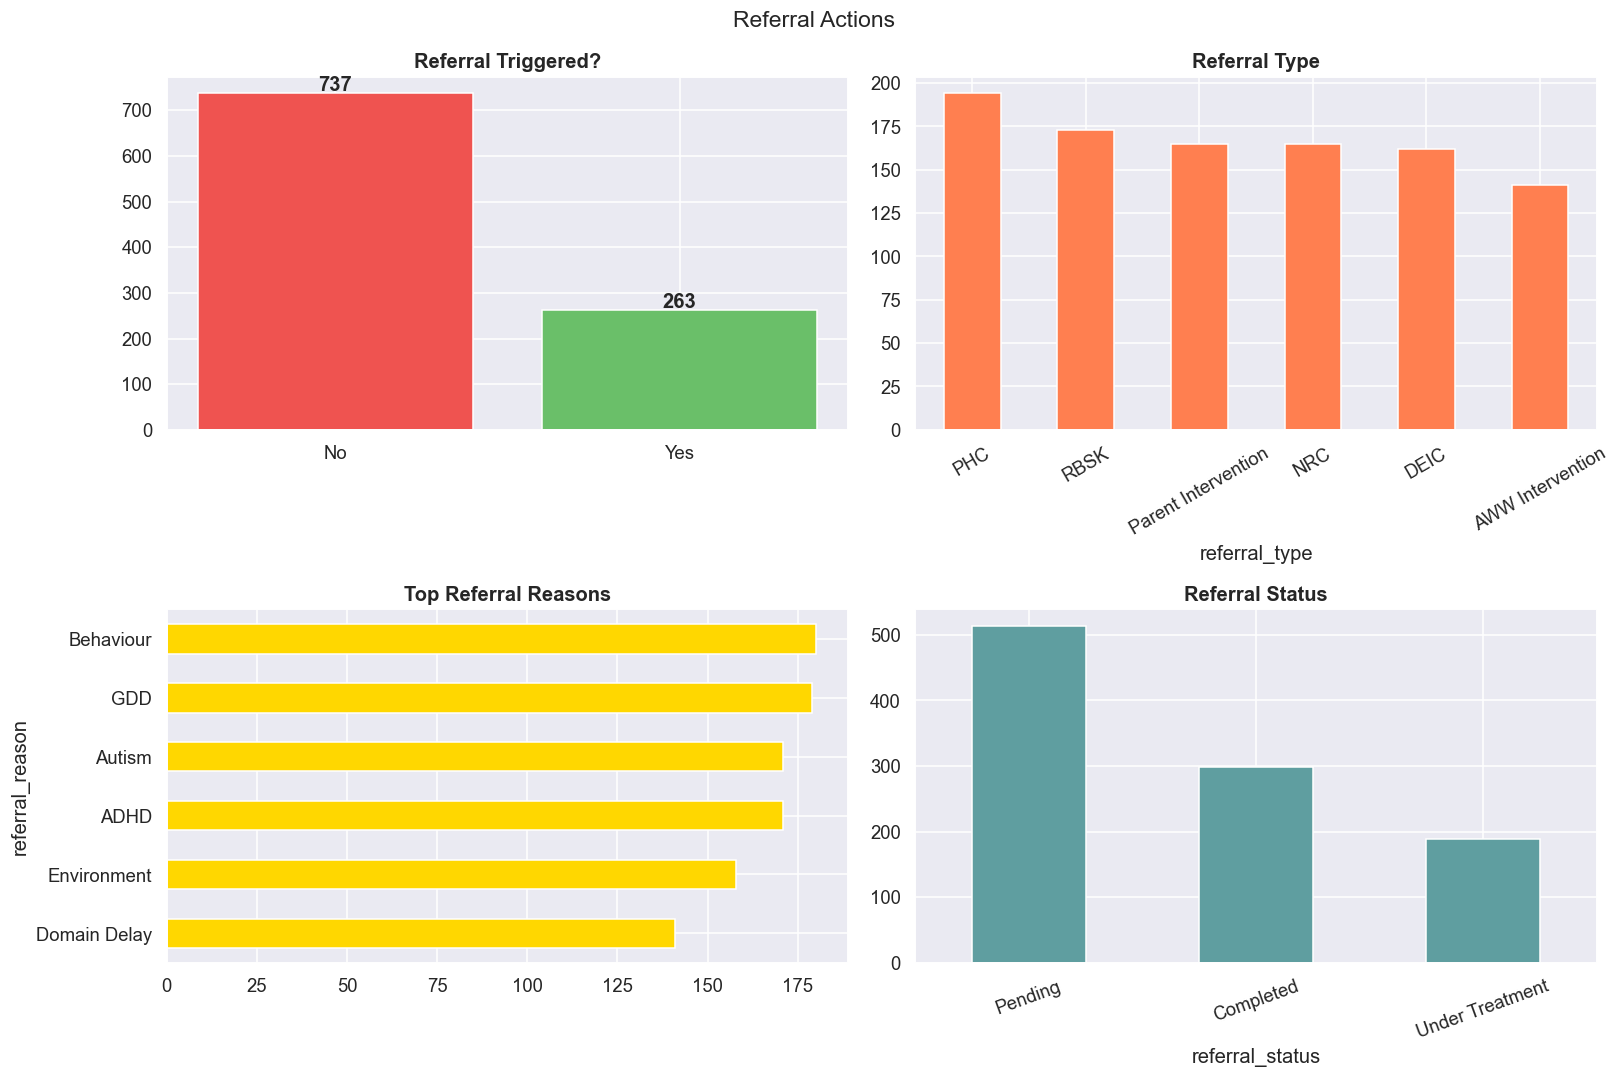

In [29]:
ref = all_sheets['Referral_Action'][['child_id','referral_triggered','referral_type',
                                      'referral_reason','referral_status']]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

# 11a  Triggered
vc = ref['referral_triggered'].value_counts()
axes[0].bar(vc.index, vc.values, color=['#ef5350','#6abf69'][:len(vc)], edgecolor='white')
axes[0].set_title('Referral Triggered?')
for i, v in enumerate(vc.values):
    axes[0].text(i, v+5, str(v), ha='center', fontweight='bold')

# 11b  Type
vc2 = ref['referral_type'].value_counts()
vc2.plot(kind='bar', ax=axes[1], color='coral', edgecolor='white', rot=30)
axes[1].set_title('Referral Type')

# 11c  Reason
vc3 = ref['referral_reason'].value_counts().head(8)
vc3.sort_values().plot(kind='barh', ax=axes[2], color='gold', edgecolor='white')
axes[2].set_title('Top Referral Reasons')

# 11d  Status
vc4 = ref['referral_status'].value_counts()
vc4.plot(kind='bar', ax=axes[3], color='cadetblue', edgecolor='white', rot=20)
axes[3].set_title('Referral Status')

plt.suptitle('Referral Actions', fontsize=15)
plt.tight_layout()
plt.show()


## 12  Intervention & Follow-Up

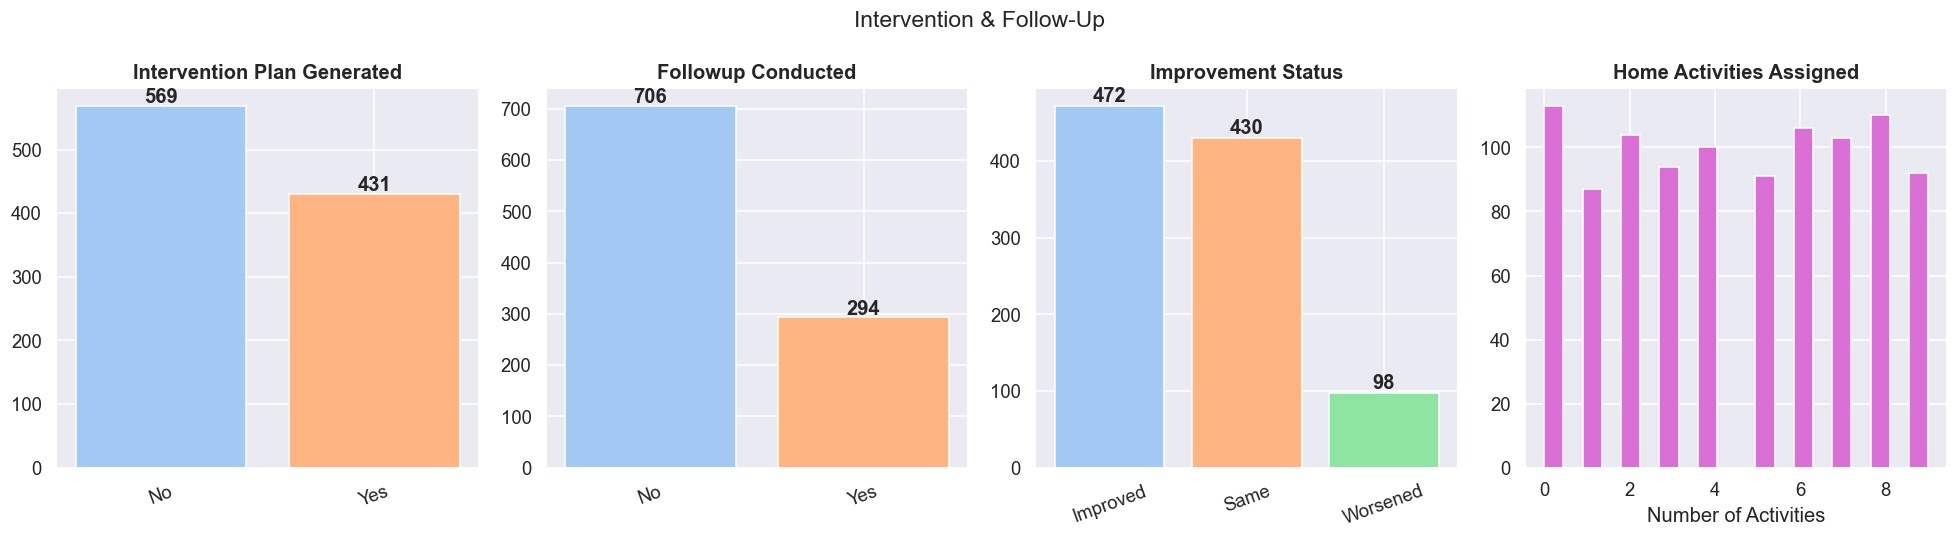

In [30]:
ifu = all_sheets['Intervention_FollowUp']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, col in zip(axes, ['intervention_plan_generated','followup_conducted',
                           'improvement_status']):
    vc = ifu[col].value_counts()
    ax.bar(vc.index, vc.values, color=sns.color_palette('pastel', len(vc)), edgecolor='white')
    ax.set_title(col.replace('_',' ').title())
    for i, v in enumerate(vc.values):
        ax.text(i, v+5, str(v), ha='center', fontweight='bold')
    ax.tick_params(axis='x', rotation=20)

axes[3].hist(ifu['home_activities_assigned'], bins=20, color='orchid', edgecolor='white')
axes[3].set_title('Home Activities Assigned')
axes[3].set_xlabel('Number of Activities')

plt.suptitle('Intervention & Follow-Up', fontsize=15)
plt.tight_layout()
plt.show()


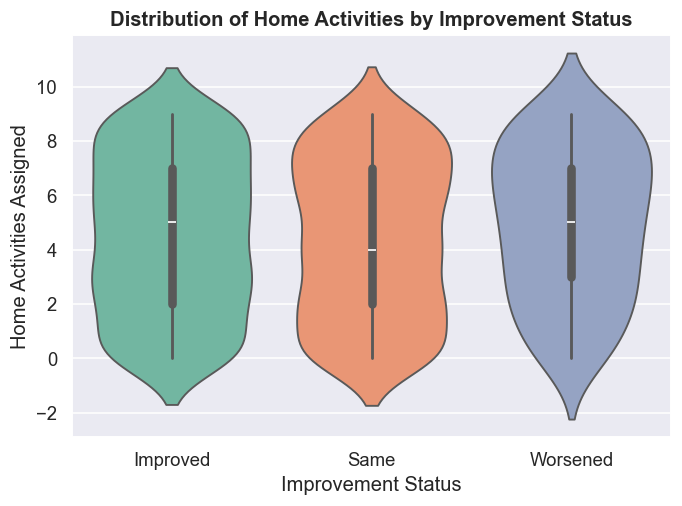

In [31]:
ifu = all_sheets['Intervention_FollowUp']

sns.violinplot(data=ifu, x='improvement_status', y='home_activities_assigned',
               palette='Set2', inner='box')
plt.title('Distribution of Home Activities by Improvement Status')
plt.xlabel('Improvement Status')
plt.ylabel('Home Activities Assigned')
plt.tight_layout()
plt.show()

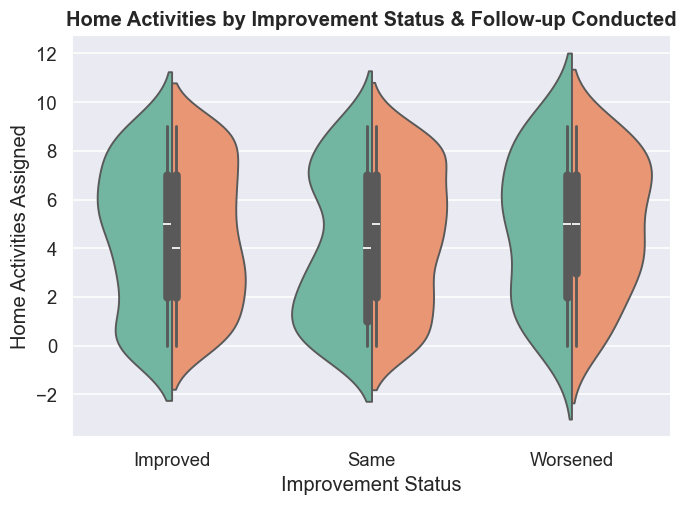

In [32]:
sns.violinplot(data=ifu, x='improvement_status', y='home_activities_assigned',
               hue='followup_conducted', palette='Set2', inner='box', split=True)
plt.title('Home Activities by Improvement Status & Follow-up Conducted')
plt.xlabel('Improvement Status')
plt.ylabel('Home Activities Assigned')
plt.gca().get_legend().remove()
plt.tight_layout()
plt.show()

## 13  Outcomes & Impact

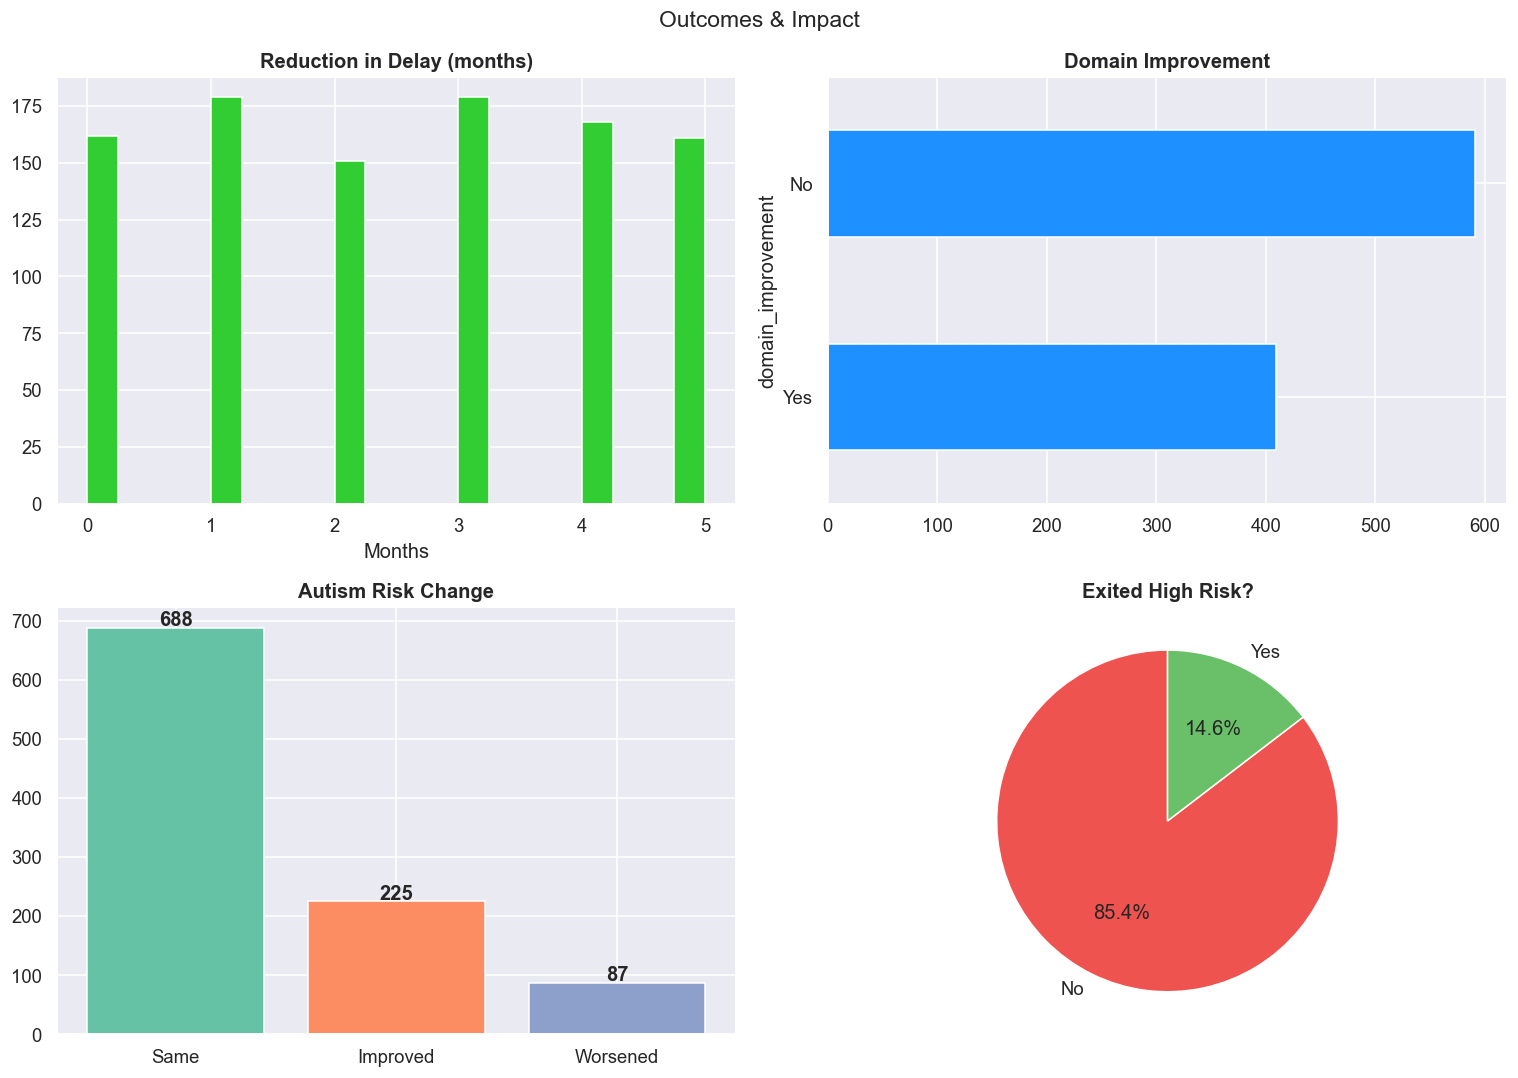

In [33]:
out = all_sheets['Outcomes_Impact']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

# 13a  Reduction in delay months histogram
axes[0].hist(out['reduction_in_delay_months'], bins=20, color='limegreen', edgecolor='white')
axes[0].set_title('Reduction in Delay (months)')
axes[0].set_xlabel('Months')

# 13b  Domain improvement
vc = out['domain_improvement'].value_counts()
vc.sort_values().plot(kind='barh', ax=axes[1], color='dodgerblue', edgecolor='white')
axes[1].set_title('Domain Improvement')

# 13c  Autism risk change
vc2 = out['autism_risk_change'].value_counts()
axes[2].bar(vc2.index, vc2.values,
            color=sns.color_palette('Set2', len(vc2)), edgecolor='white')
axes[2].set_title('Autism Risk Change')
for i, v in enumerate(vc2.values):
    axes[2].text(i, v+3, str(v), ha='center', fontweight='bold')

# 13d  Exit high risk
vc3 = out['exit_high_risk'].value_counts()
axes[3].pie(vc3, labels=vc3.index, autopct='%1.1f%%', startangle=90,
            colors=['#ef5350','#6abf69'][:len(vc3)])
axes[3].set_title('Exited High Risk?')

plt.suptitle('Outcomes & Impact', fontsize=15)
plt.tight_layout()
plt.show()


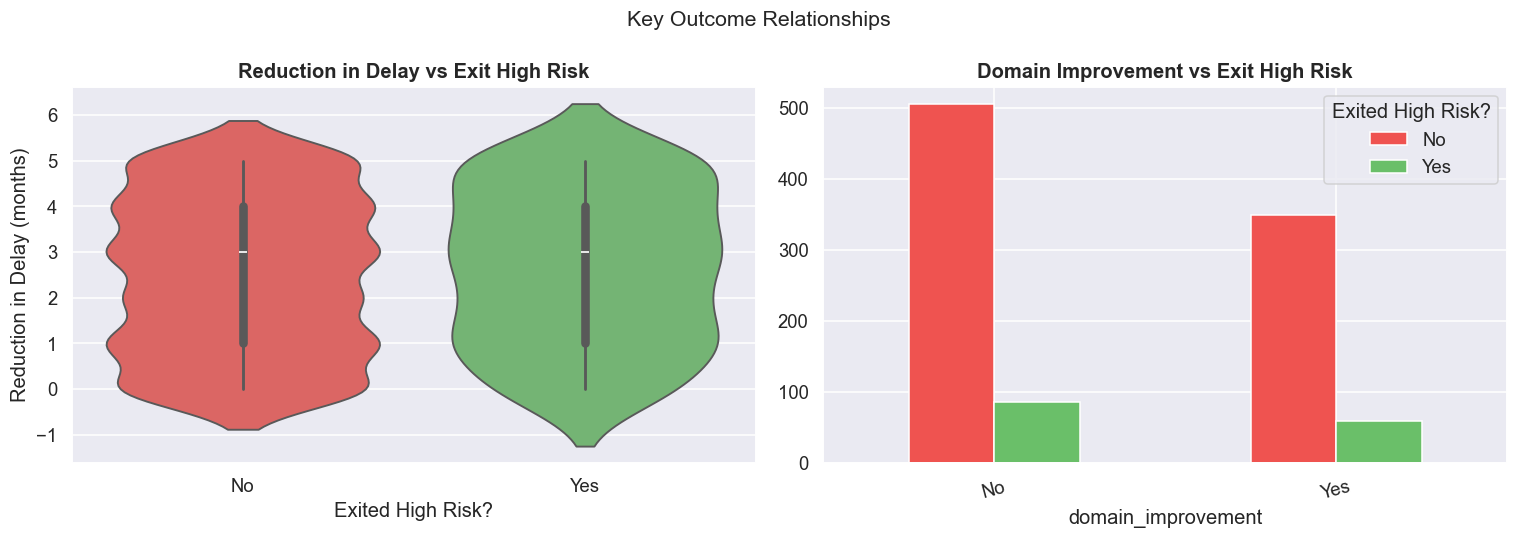

In [34]:
out = all_sheets['Outcomes_Impact']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# reduction_in_delay_months vs exit_high_risk
sns.violinplot(data=out, x='exit_high_risk', y='reduction_in_delay_months',
               palette=['#ef5350','#6abf69'], inner='box', ax=axes[0])
axes[0].set_title('Reduction in Delay vs Exit High Risk')
axes[0].set_xlabel('Exited High Risk?')
axes[0].set_ylabel('Reduction in Delay (months)')

# domain_improvement vs exit_high_risk
pd.crosstab(out['domain_improvement'], out['exit_high_risk']).plot(
    kind='bar', ax=axes[1], color=['#ef5350','#6abf69'], edgecolor='white', rot=15)
axes[1].set_title('Domain Improvement vs Exit High Risk')
axes[1].legend(title='Exited High Risk?')

plt.suptitle('Key Outcome Relationships', fontsize=14)
plt.tight_layout()
plt.show()

## 14  🔗 Cross-Sheet Deep Dive (Merged Analysis)
Merging key sheets on `child_id` to find relationships between domains.

In [50]:
master = (all_sheets['Registration']
          .merge(all_sheets['Developmental_Risk'], on='child_id')
          .merge(all_sheets['Neuro_Behavioral'], on='child_id')
          .merge(all_sheets['Nutrition'], on='child_id')
          .merge(all_sheets['Environment_Caregiving'], on='child_id')
          .merge(all_sheets['Developmental_Assessment'], on='child_id')
          .merge(all_sheets['Risk_Classification'], on='child_id')
          .merge(all_sheets['Behaviour_Indicators'], on='child_id')
          .merge(all_sheets['Baseline_Risk_Output'][['child_id','baseline_score','baseline_category']], on='child_id')
          .merge(all_sheets['Referral_Action'][['child_id','referral_triggered','referral_type',
                                                'referral_reason','referral_status']], on='child_id')
          .merge(all_sheets['Intervention_FollowUp'], on='child_id')
          .merge(all_sheets['Outcomes_Impact'], on='child_id'))

print("Master shape:", master.shape)
print("Columns:", list(master.columns))
print("Master shape:", master.shape)
master.head(3)


Master shape: (1000, 62)
Columns: ['child_id', 'dob', 'age_months', 'gender', 'awc_code', 'mandal', 'district', 'assessment_cycle', 'GM_delay', 'FM_delay', 'LC_delay', 'COG_delay', 'SE_delay', 'num_delays', 'autism_risk_x', 'adhd_risk', 'behavior_risk', 'underweight', 'stunting', 'wasting', 'anemia', 'nutrition_score', 'nutrition_risk', 'parent_child_interaction_score', 'parent_mental_health_score', 'home_stimulation_score', 'play_materials', 'caregiver_engagement', 'language_exposure', 'safe_water', 'toilet_facility', 'mode_delivery', 'mode_conception', 'birth_status', 'consanguinity', 'GM_DQ', 'FM_DQ', 'LC_DQ', 'COG_DQ', 'SE_DQ', 'Composite_DQ', 'developmental_status', 'autism_risk_y', 'attention_regulation_risk', 'nutrition_linked_risk', 'behaviour_concerns', 'behaviour_score', 'behaviour_risk_level', 'baseline_score', 'baseline_category', 'referral_triggered', 'referral_type', 'referral_reason', 'referral_status', 'intervention_plan_generated', 'home_activities_assigned', 'followup

,child_id,dob,age_months,gender,awc_code,mandal,district,assessment_cycle,GM_delay,FM_delay,LC_delay,COG_delay,SE_delay,num_delays,autism_risk_x,adhd_risk,behavior_risk,underweight,stunting,wasting,anemia,nutrition_score,nutrition_risk,parent_child_interaction_score,parent_mental_health_score,home_stimulation_score,play_materials,caregiver_engagement,language_exposure,safe_water,toilet_facility,mode_delivery,mode_conception,birth_status,consanguinity,GM_DQ,FM_DQ,LC_DQ,COG_DQ,SE_DQ,Composite_DQ,developmental_status,autism_risk_y,attention_regulation_risk,nutrition_linked_risk,behaviour_concerns,behaviour_score,behaviour_risk_level,baseline_score,baseline_category,referral_triggered,referral_type,referral_reason,referral_status,intervention_plan_generated,home_activities_assigned,followup_conducted,improvement_status,reduction_in_delay_months,domain_improvement,autism_risk_change,exit_high_risk
0,AP_ECD_000001,2022-01-24,62,F,1001,Mandal_B,Chittoor,Baseline,0,0,0,0,0,0,Low,High,High,0,0,0,0,0,Low,3,2,6,Yes,Medium,Inadequate,No,Yes,C-section,Natural,Term,No,79.503859,73.880759,130.000000,83.925931,76.013575,88.664825,No Delay,Low,No,Underweight,NaN,0,Low,15,Medium,No,PHC,GDD,Under Treatment,Yes,5,Yes,Improved,1,No,Same,No
1,AP_ECD_000002,2024-08-18,17,M,1172,Mandal_B,Guntur,Baseline,0,0,0,0,0,0,Moderate,Low,High,1,1,0,0,5,High,4,2,5,Yes,Medium,Adequate,No,Yes,C-section,Natural,Term,No,112.622085,99.832217,104.943911,83.384866,91.354319,98.427480,No Delay,Low,No,Underweight,Sleep,14,High,15,Medium,No,Parent Intervention,ADHD,Pending,Yes,3,No,Improved,5,No,Same,Yes
2,AP_ECD_000003,2022-11-24,9,M,1173,Mandal_B,Guntur,Follow-up,0,0,1,0,1,2,Moderate,Low,High,1,1,0,0,5,High,1,8,4,Yes,Medium,Adequate,No,Yes,Vaginal,ART,Term,No,82.183310,91.989292,70.700197,95.086873,88.504365,85.692808,1 delay,Low,No,Underweight,NaN,6,Moderate,25,Medium,No,AWW Intervention,GDD,Completed,Yes,7,No,Improved,1,Yes,Same,No


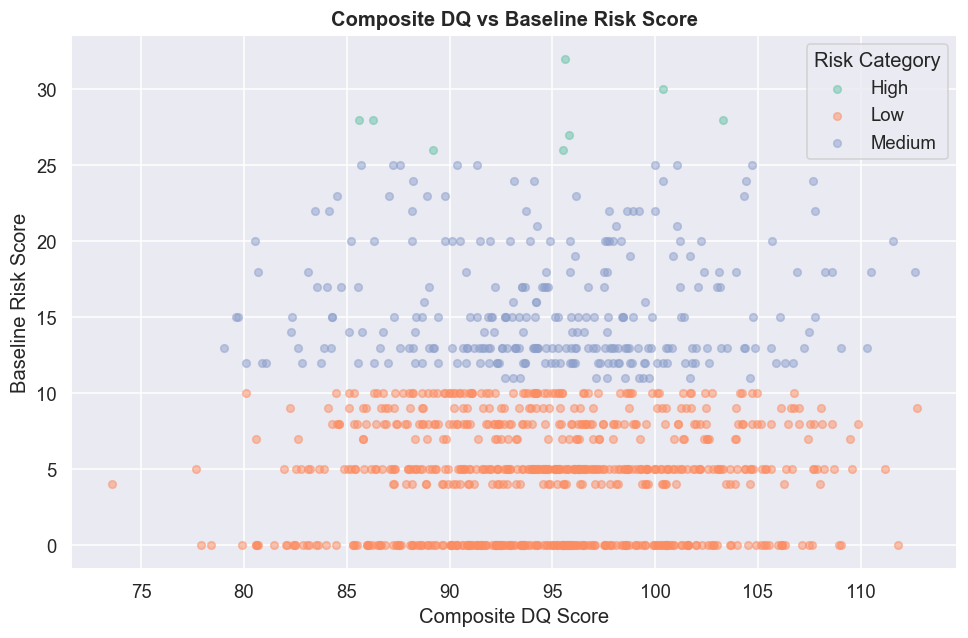

In [36]:
# 14a  Baseline score vs Composite DQ scatter (coloured by baseline category)
fig, ax = plt.subplots(figsize=(9, 6))
for cat, grp in master.groupby('baseline_category'):
    ax.scatter(grp['Composite_DQ'], grp['baseline_score'],
               label=cat, alpha=0.5, s=25)
ax.set_xlabel('Composite DQ Score')
ax.set_ylabel('Baseline Risk Score')
ax.set_title('Composite DQ vs Baseline Risk Score')
ax.legend(title='Risk Category')
plt.tight_layout()
plt.show()


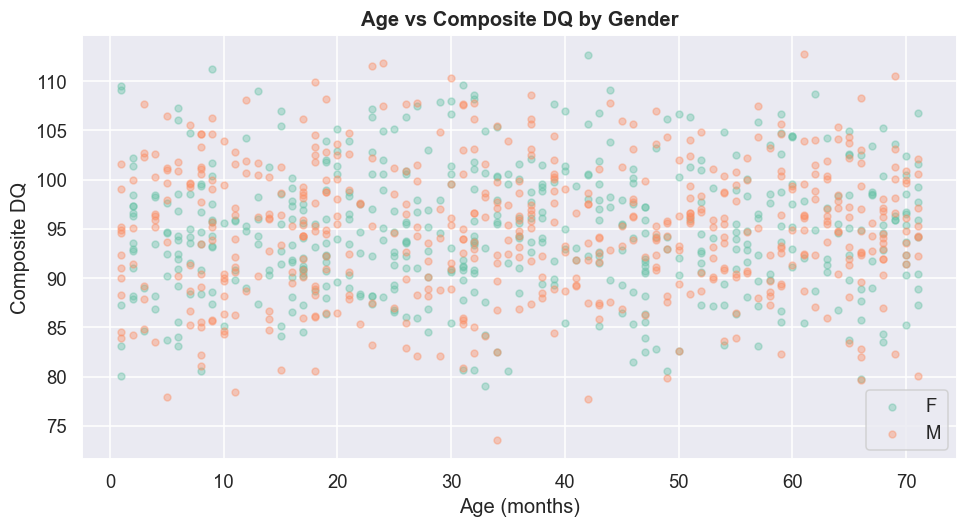

In [37]:
# 14b  Age vs Composite DQ scatter, coloured by gender
fig, ax = plt.subplots(figsize=(9, 5))
for gender, grp in master.groupby('gender'):
    ax.scatter(grp['age_months'], grp['Composite_DQ'],
               label=gender, alpha=0.4, s=20)
ax.set_xlabel('Age (months)')
ax.set_ylabel('Composite DQ')
ax.set_title('Age vs Composite DQ by Gender')
ax.legend()
plt.tight_layout()
plt.show()


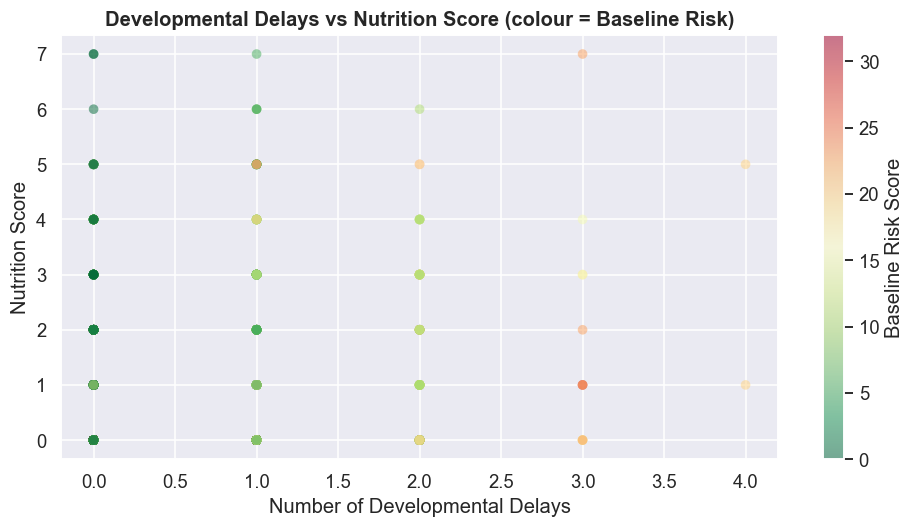

In [38]:
# 14c  Num delays vs Nutrition score scatter (sized by baseline score)
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(master['num_delays'], master['nutrition_score'],
                c=master['baseline_score'], cmap='RdYlGn_r',
                alpha=0.5, s=40, edgecolors='none')
plt.colorbar(sc, ax=ax, label='Baseline Risk Score')
ax.set_xlabel('Number of Developmental Delays')
ax.set_ylabel('Nutrition Score')
ax.set_title('Developmental Delays vs Nutrition Score (colour = Baseline Risk)')
plt.tight_layout()
plt.show()


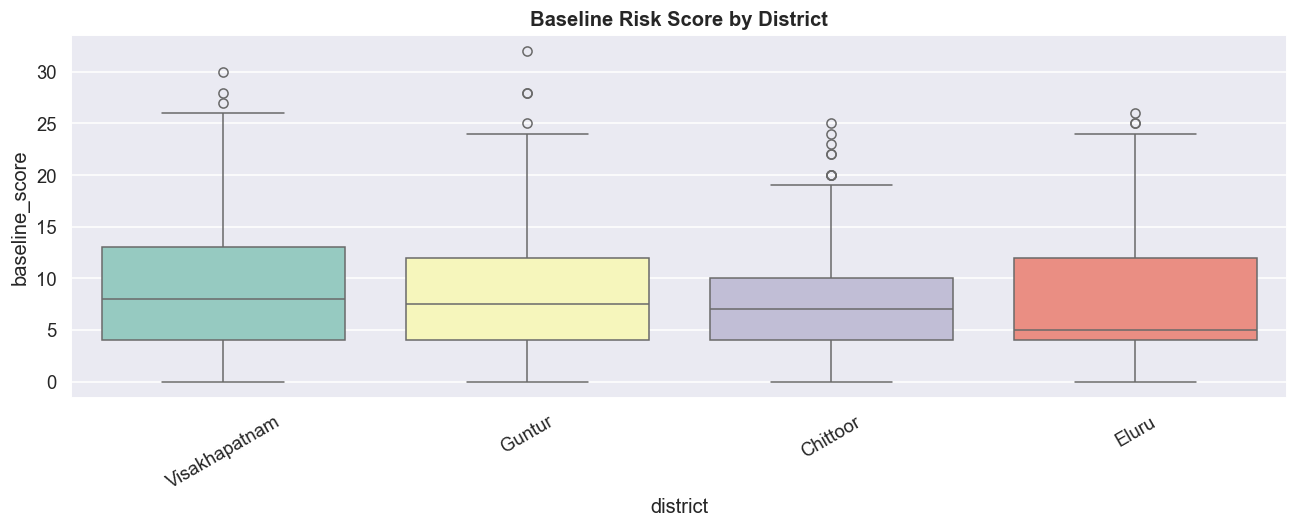

In [39]:
# 14d  Baseline score by district (box)
fig, ax = plt.subplots(figsize=(12, 5))
order_d = master.groupby('district')['baseline_score'].median().sort_values(ascending=False).index
sns.boxplot(data=master, x='district', y='baseline_score',
            order=order_d, palette='Set3', ax=ax)
ax.set_title('Baseline Risk Score by District')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


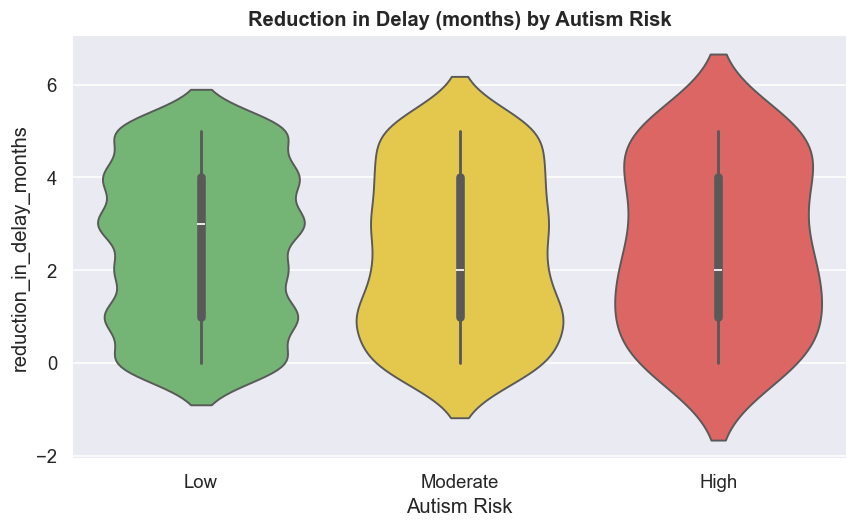

In [40]:
# 14e  Reduction in delay months by autism risk (violin)
fig, ax = plt.subplots(figsize=(8, 5))
order_ar = ['Low','Moderate','High']
sns.violinplot(data=master, x='autism_risk', y='reduction_in_delay_months',
               order=order_ar, palette=['#6abf69','#fdd835','#ef5350'],
               inner='box', ax=ax)
ax.set_title('Reduction in Delay (months) by Autism Risk')
ax.set_xlabel('Autism Risk')
plt.tight_layout()
plt.show()


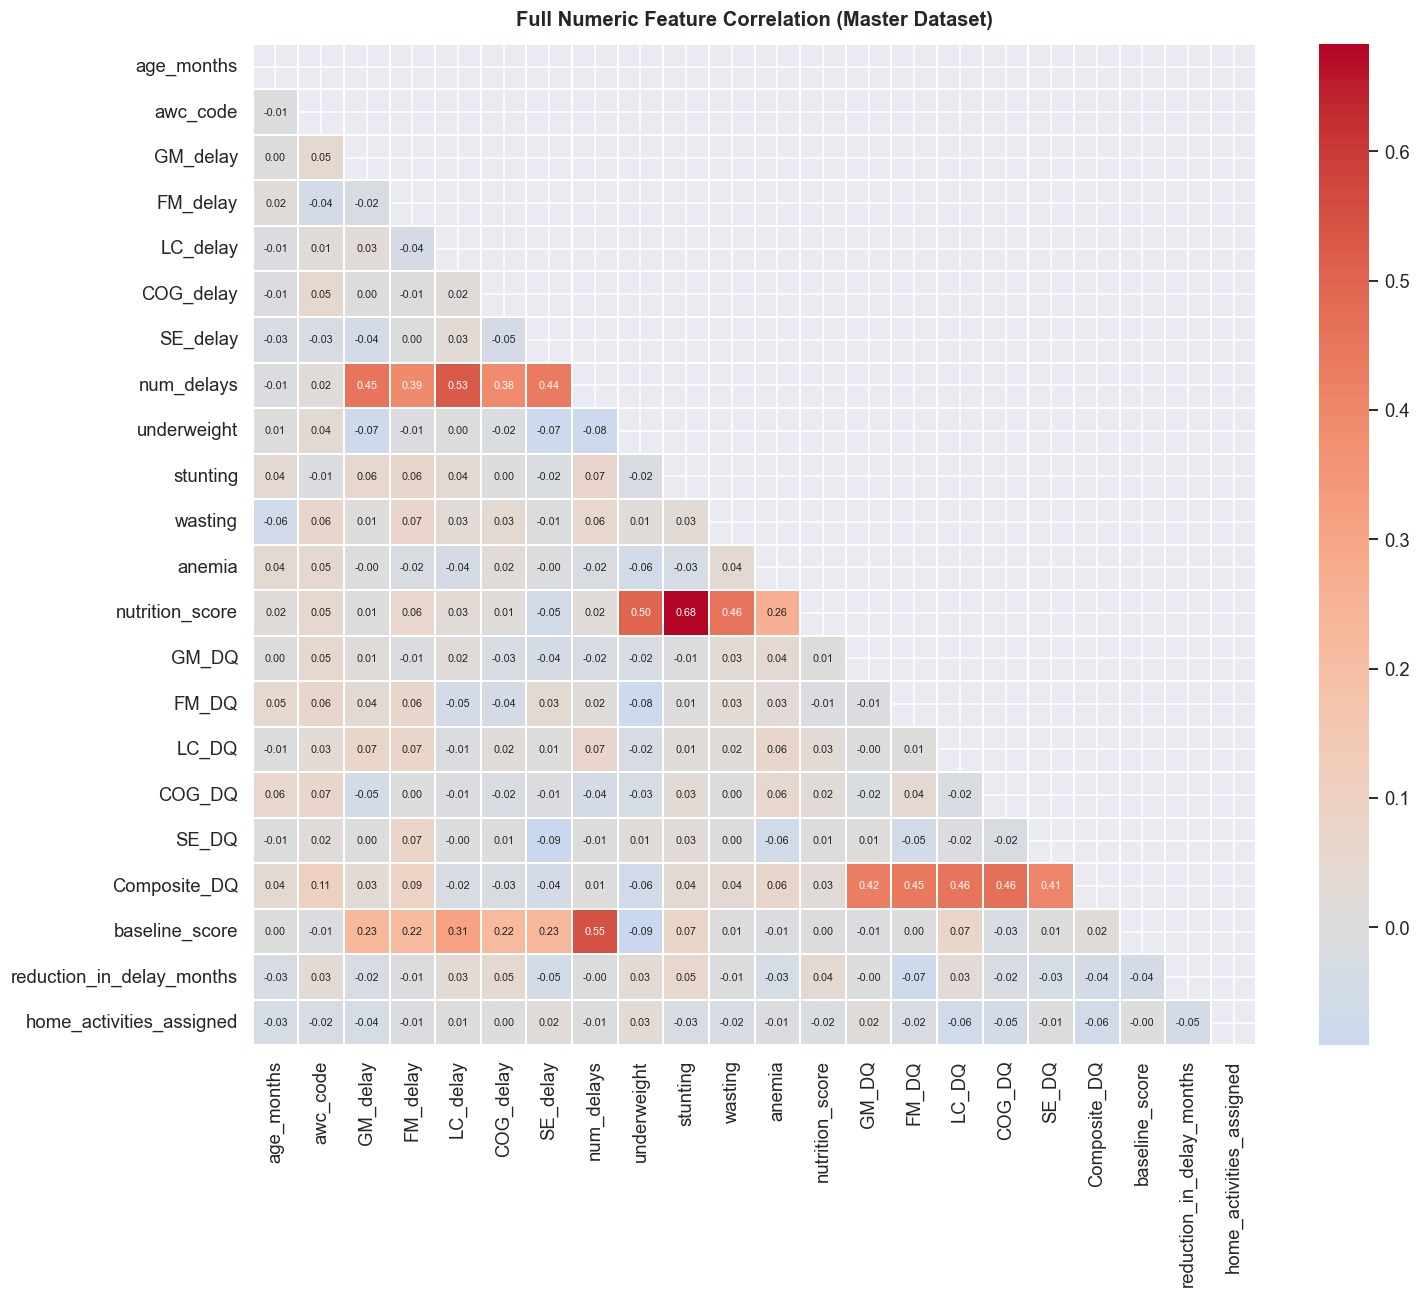

In [41]:
# 14f  Full numeric correlation heatmap (master)
num_master = master.select_dtypes(include='number')
corr_m = num_master.corr()
fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_m, dtype=bool))
sns.heatmap(corr_m, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=.3,
            annot_kws={'size': 7}, ax=ax)
ax.set_title('Full Numeric Feature Correlation (Master Dataset)', pad=12)
plt.tight_layout()
plt.show()


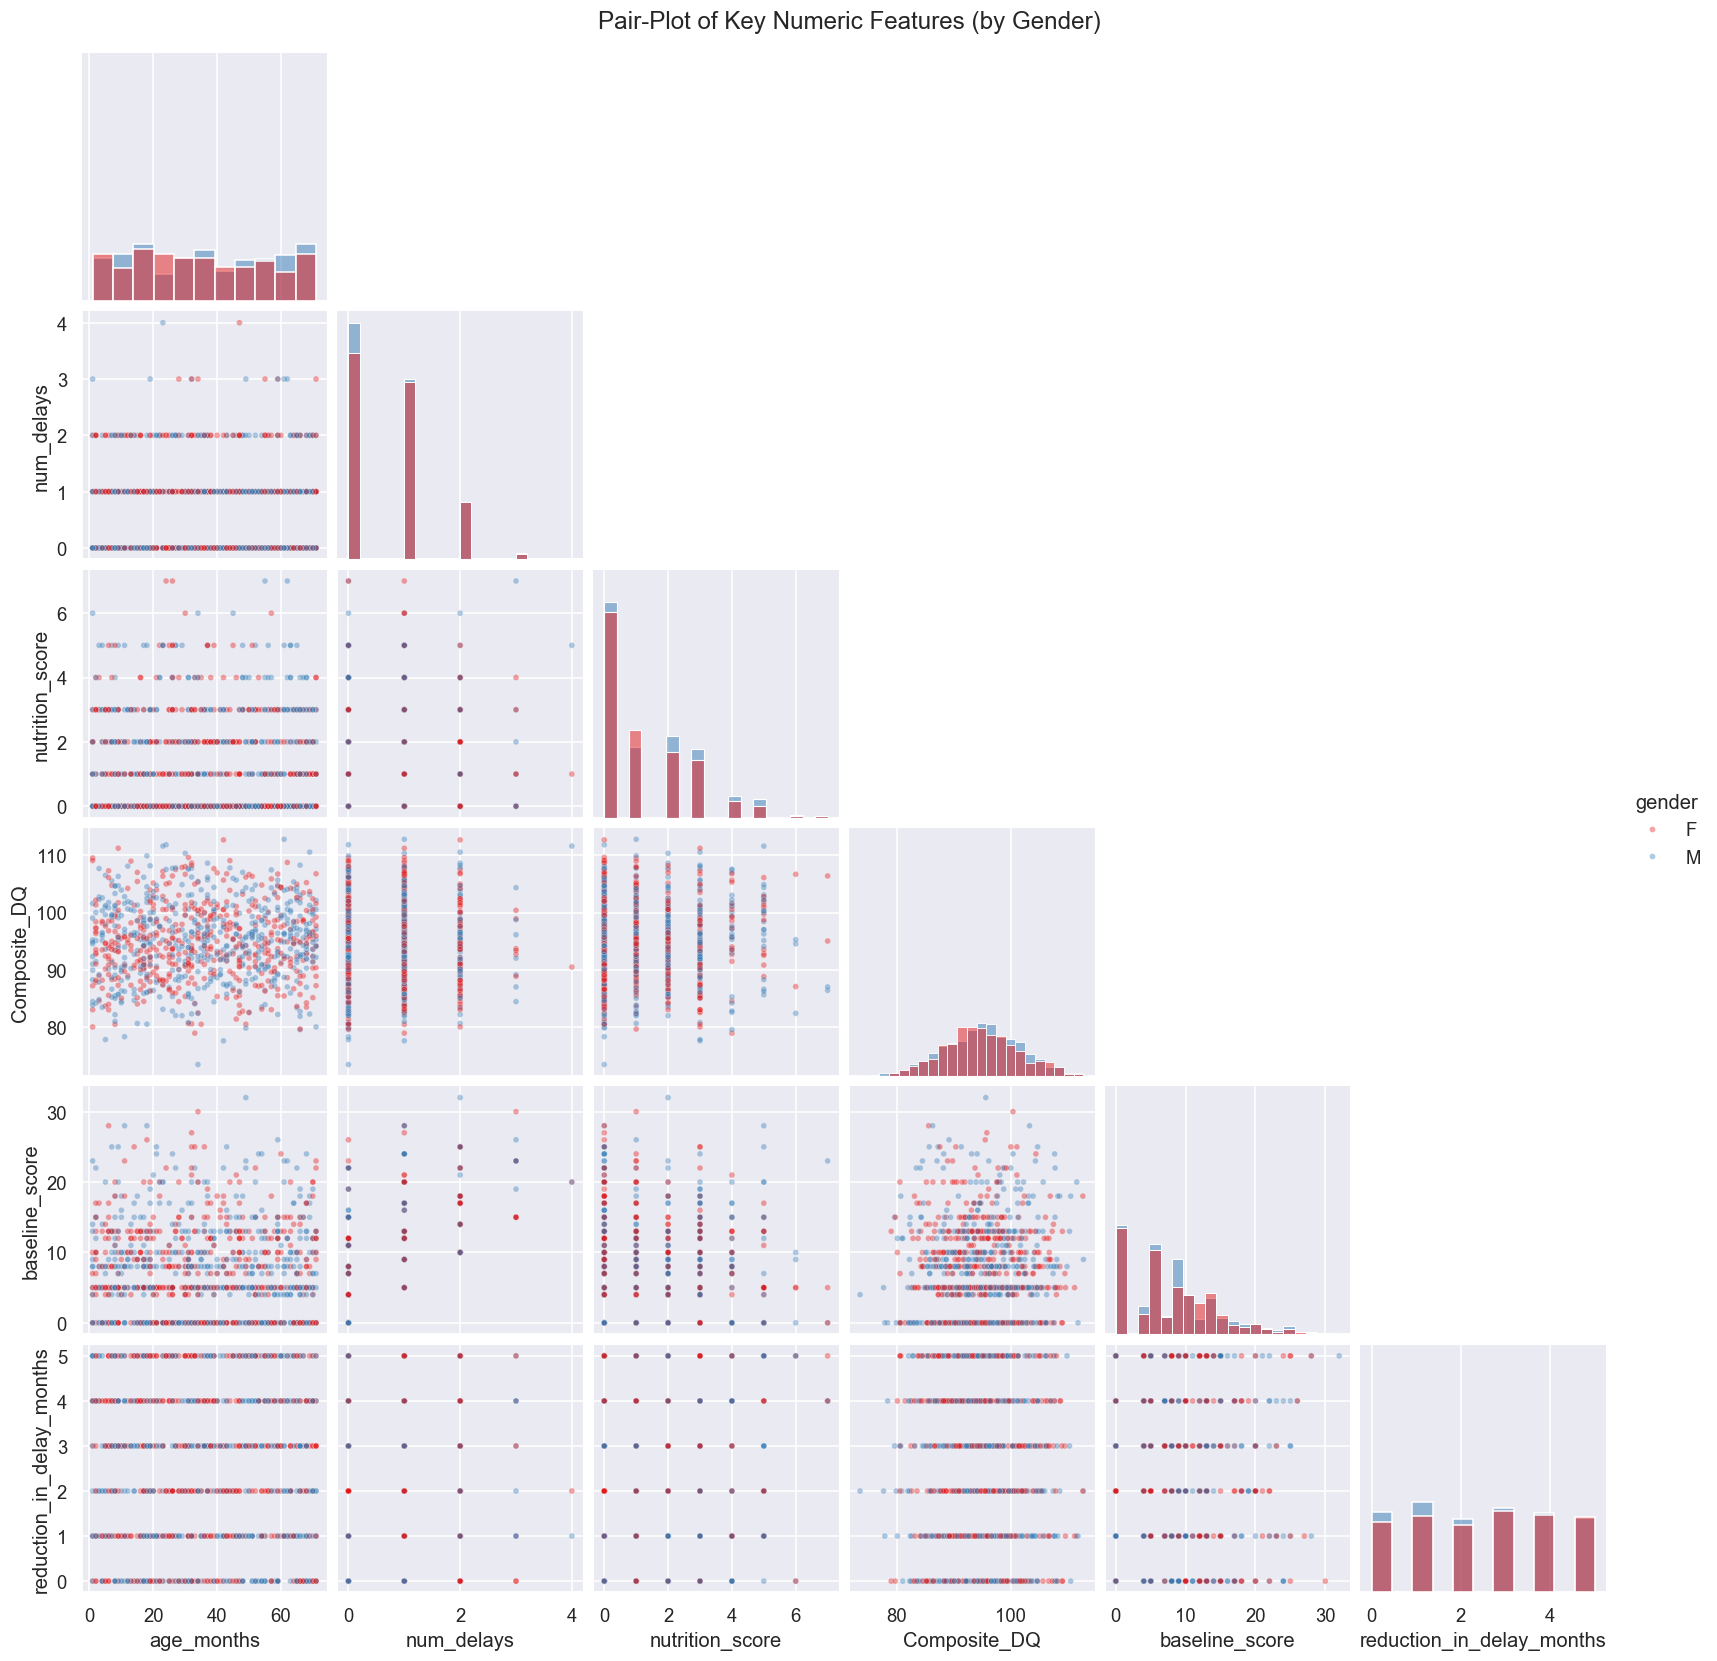

In [42]:
# 14g  Pair-plot of key scores
key_cols = ['age_months','num_delays','nutrition_score',
            'Composite_DQ','baseline_score','reduction_in_delay_months']
pair_df = master[key_cols + ['gender']].dropna()
g = sns.pairplot(pair_df, hue='gender', vars=key_cols,
                 diag_kind='hist', plot_kws={'alpha':0.4, 's':15},
                 palette='Set1', corner=True)
g.fig.suptitle('Pair-Plot of Key Numeric Features (by Gender)', y=1.01)
plt.show()


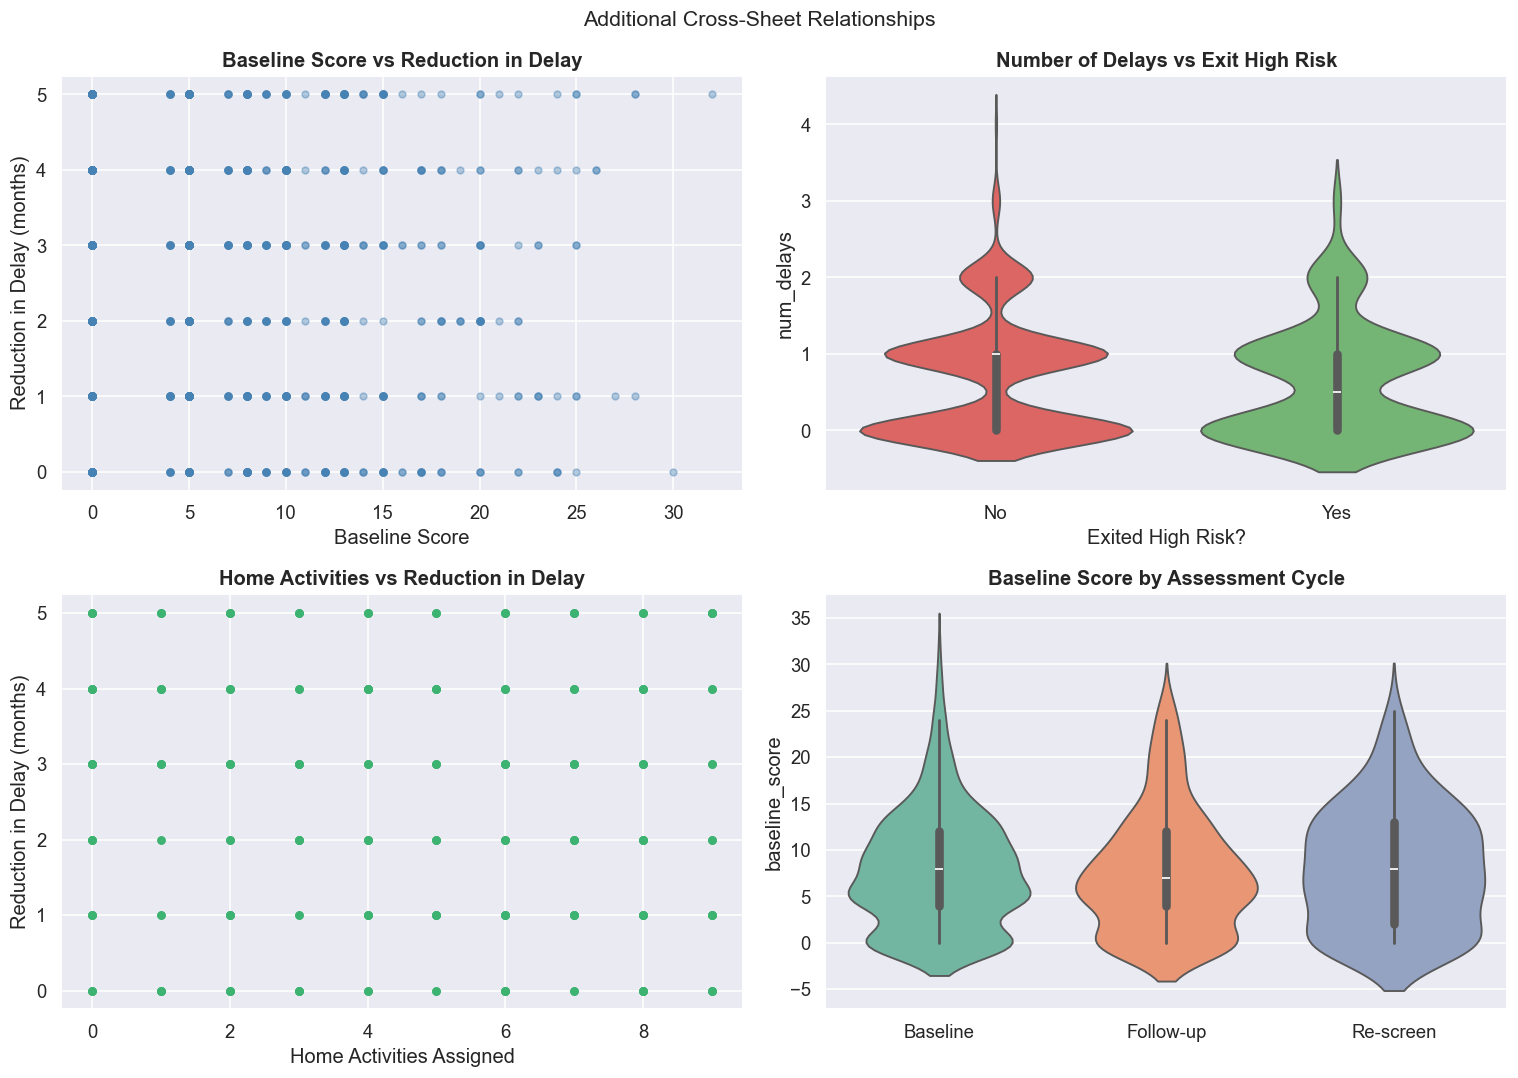

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

# 1. baseline_score vs reduction_in_delay_months
axes[0].scatter(master['baseline_score'], master['reduction_in_delay_months'],
                alpha=0.4, color='steelblue', s=20)
axes[0].set_title('Baseline Score vs Reduction in Delay')
axes[0].set_xlabel('Baseline Score')
axes[0].set_ylabel('Reduction in Delay (months)')

# 2. num_delays vs exit_high_risk
sns.violinplot(data=master, x='exit_high_risk', y='num_delays',
               palette=['#ef5350','#6abf69'], inner='box', ax=axes[1])
axes[1].set_title('Number of Delays vs Exit High Risk')
axes[1].set_xlabel('Exited High Risk?')

# 3. home_activities_assigned vs reduction_in_delay_months
axes[2].scatter(master['home_activities_assigned'], master['reduction_in_delay_months'],
                alpha=0.4, color='mediumseagreen', s=20)
axes[2].set_title('Home Activities vs Reduction in Delay')
axes[2].set_xlabel('Home Activities Assigned')
axes[2].set_ylabel('Reduction in Delay (months)')

# 4. assessment_cycle vs baseline_score
sns.violinplot(data=master, x='assessment_cycle', y='baseline_score',
               palette='Set2', inner='box', ax=axes[3])
axes[3].set_title('Baseline Score by Assessment Cycle')
axes[3].set_xlabel('')

plt.suptitle('Additional Cross-Sheet Relationships', fontsize=14)
plt.tight_layout()
plt.show()

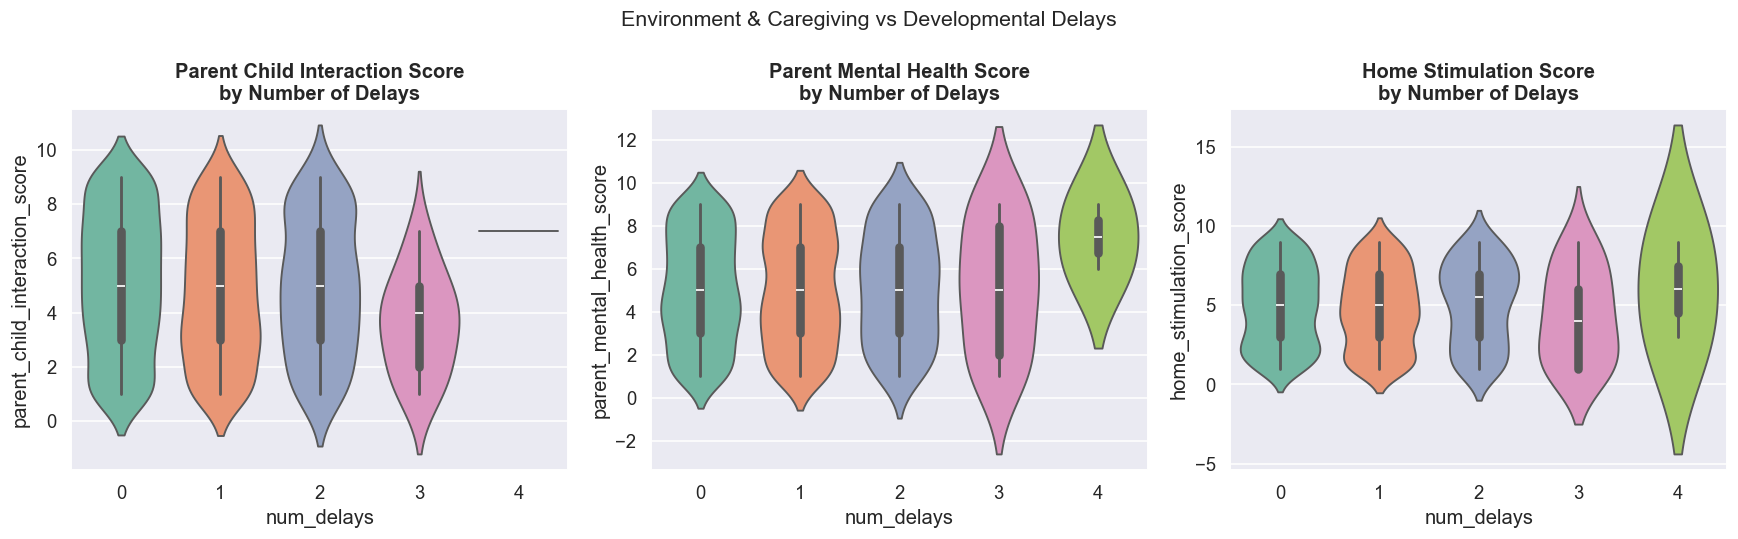

In [46]:
merged_env_dev = (all_sheets['Environment_Caregiving']
                  .merge(all_sheets['Developmental_Risk'], on='child_id'))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, env_col in zip(axes, env_score_cols):
    sns.violinplot(data=merged_env_dev, x='num_delays', y=env_col,
                   palette='Set2', inner='box', ax=ax)
    ax.set_title(f'{env_col.replace("_"," ").title()}\nby Number of Delays')
plt.suptitle('Environment & Caregiving vs Developmental Delays', fontsize=14)
plt.tight_layout()
plt.show()

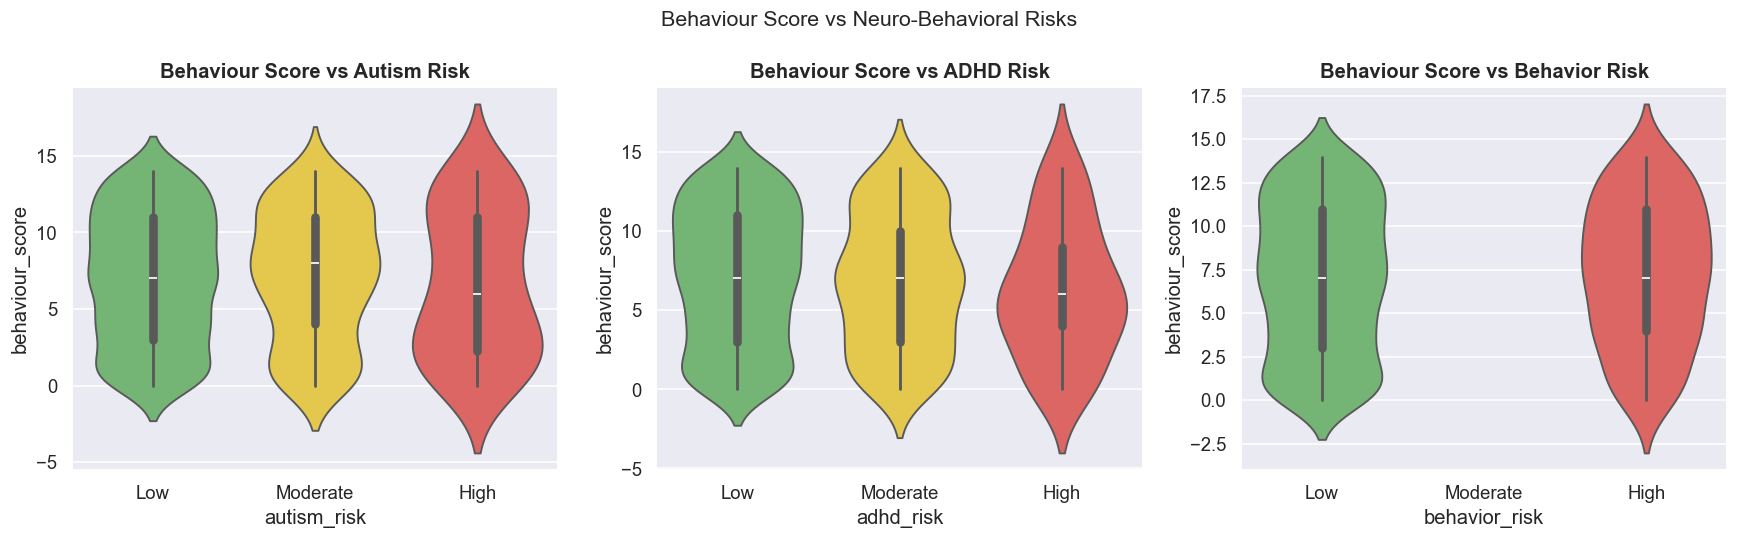

In [48]:
merged_beh_nb = (all_sheets['Behaviour_Indicators']
                 .merge(all_sheets['Neuro_Behavioral'], on='child_id'))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, label in zip(axes,
                           ['autism_risk','adhd_risk','behavior_risk'],
                           ['Autism Risk','ADHD Risk','Behavior Risk']):
    sns.violinplot(data=merged_beh_nb, x=col, y='behaviour_score',
                   order=['Low','Moderate','High'],
                   palette=['#6abf69','#fdd835','#ef5350'],
                   inner='box', ax=ax)
    ax.set_title(f'Behaviour Score vs {label}')
plt.suptitle('Behaviour Score vs Neuro-Behavioral Risks', fontsize=14)
plt.tight_layout()
plt.show()

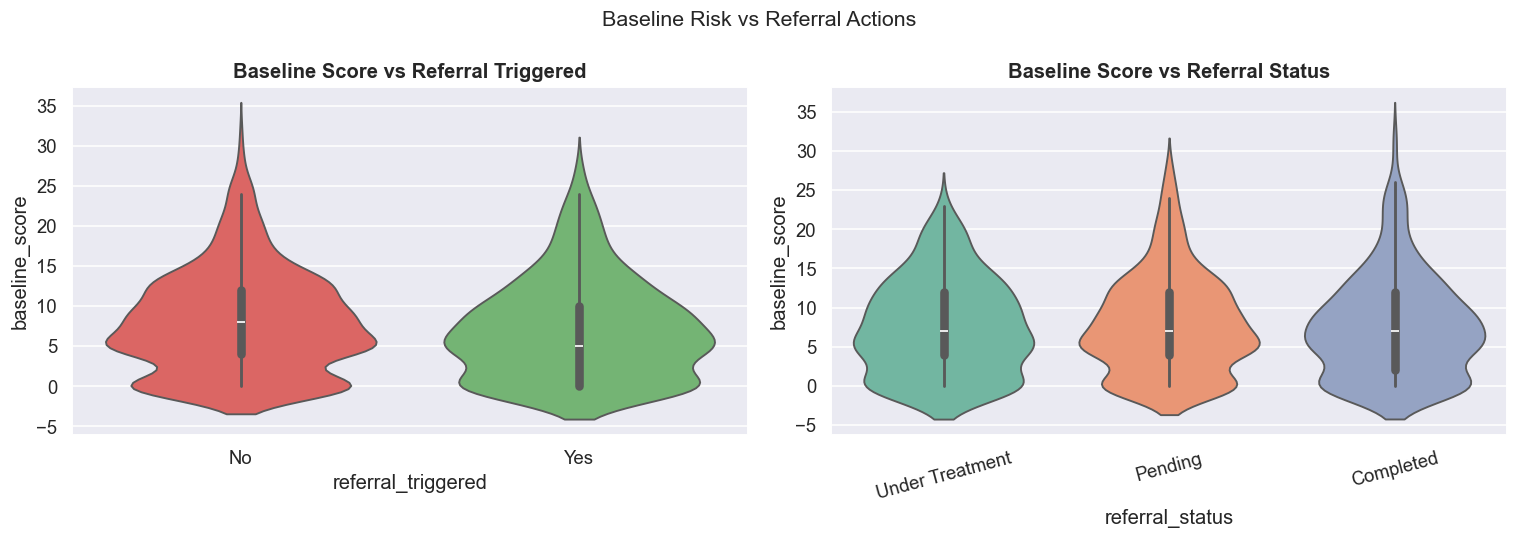

In [49]:
merged_ref = (all_sheets['Baseline_Risk_Output'][['child_id','baseline_score']]
              .merge(all_sheets['Referral_Action'][['child_id','referral_triggered',
                                                    'referral_status']], on='child_id'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(data=merged_ref, x='referral_triggered', y='baseline_score',
               palette=['#ef5350','#6abf69'], inner='box', ax=axes[0])
axes[0].set_title('Baseline Score vs Referral Triggered')

sns.violinplot(data=merged_ref, x='referral_status', y='baseline_score',
               palette='Set2', inner='box', ax=axes[1])
axes[1].set_title('Baseline Score vs Referral Status')
axes[1].tick_params(axis='x', rotation=15)

plt.suptitle('Baseline Risk vs Referral Actions', fontsize=14)
plt.tight_layout()
plt.show()

## 15  Summary Statistics — Numeric Features

In [45]:
summary = num_master.describe().T
summary['skew'] = num_master.skew()
summary['kurtosis'] = num_master.kurtosis()

summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age_months,1000.0,35.69,20.73,1.00,18.00,35.00,54.00,71.00,0.06,-1.21
awc_code,1000.0,1100.82,57.45,1000.00,1050.75,1102.50,1152.00,1199.00,-0.01,-1.21
GM_delay,1000.0,0.15,0.35,0.00,0.00,0.00,0.00,1.00,2.01,2.04
FM_delay,1000.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00,2.42,3.85
LC_delay,1000.0,0.18,0.39,0.00,0.00,0.00,0.00,1.00,1.65,0.73
COG_delay,1000.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00,2.67,5.14
SE_delay,1000.0,0.14,0.34,0.00,0.00,0.00,0.00,1.00,2.11,2.48
num_delays,1000.0,0.68,0.75,0.00,0.00,1.00,1.00,4.00,0.90,0.43
underweight,1000.0,0.19,0.39,0.00,0.00,0.00,0.00,1.00,1.58,0.51
stunting,1000.0,0.14,0.35,0.00,0.00,0.00,0.00,1.00,2.10,2.42


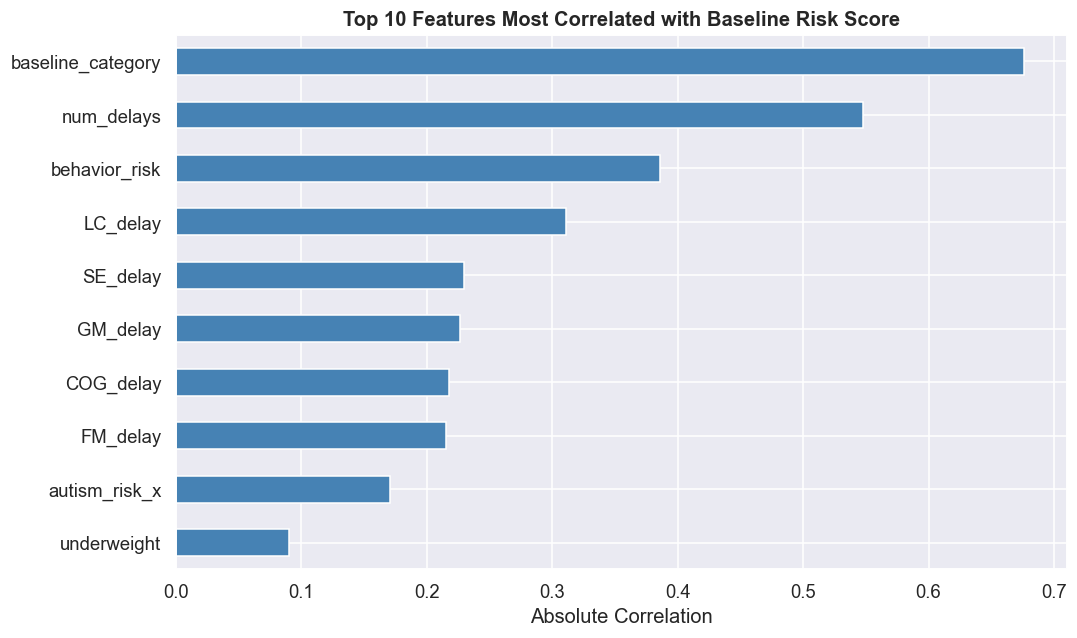

In [51]:
from sklearn.preprocessing import LabelEncoder

risk_df = master.copy()

# Encode categoricals
le = LabelEncoder()
for col in risk_df.select_dtypes(include='object').columns:
    risk_df[col] = le.fit_transform(risk_df[col].astype(str))

# Correlation with baseline_score
corr = risk_df.corr()['baseline_score'].drop('baseline_score')
corr_sorted = corr.abs().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
corr_sorted.sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Top 10 Features Most Correlated with Baseline Risk Score')
ax.set_xlabel('Absolute Correlation')
plt.tight_layout()
plt.show()

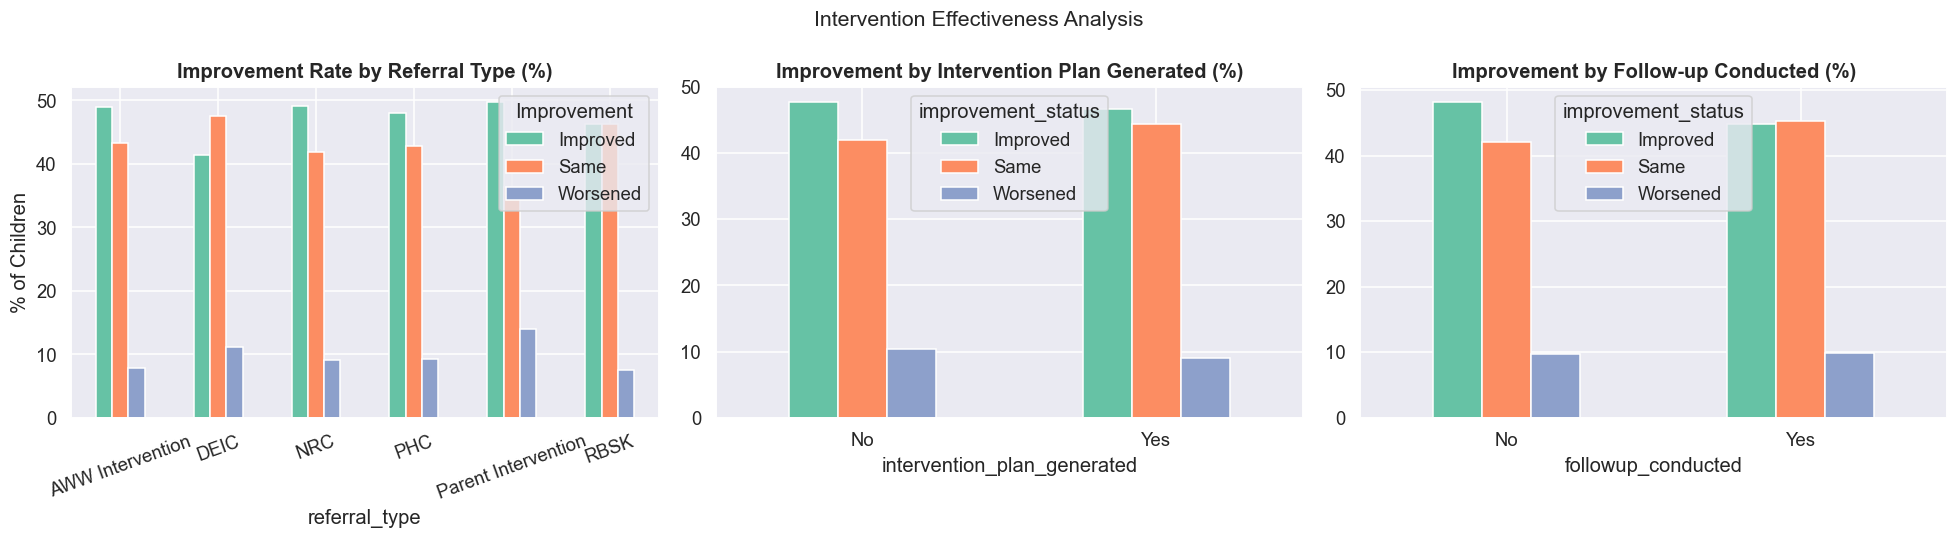

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Improvement by referral type
pd.crosstab(master['referral_type'], master['improvement_status'],
            normalize='index').mul(100).plot(kind='bar', ax=axes[0],
            edgecolor='white', rot=20)
axes[0].set_title('Improvement Rate by Referral Type (%)')
axes[0].set_ylabel('% of Children')
axes[0].legend(title='Improvement')

# Improvement by intervention plan
pd.crosstab(master['intervention_plan_generated'], master['improvement_status'],
            normalize='index').mul(100).plot(kind='bar', ax=axes[1],
            edgecolor='white', rot=0)
axes[1].set_title('Improvement by Intervention Plan Generated (%)')

# Improvement by followup conducted
pd.crosstab(master['followup_conducted'], master['improvement_status'],
            normalize='index').mul(100).plot(kind='bar', ax=axes[2],
            edgecolor='white', rot=0)
axes[2].set_title('Improvement by Follow-up Conducted (%)')

plt.suptitle('Intervention Effectiveness Analysis', fontsize=14)
plt.tight_layout()
plt.show()

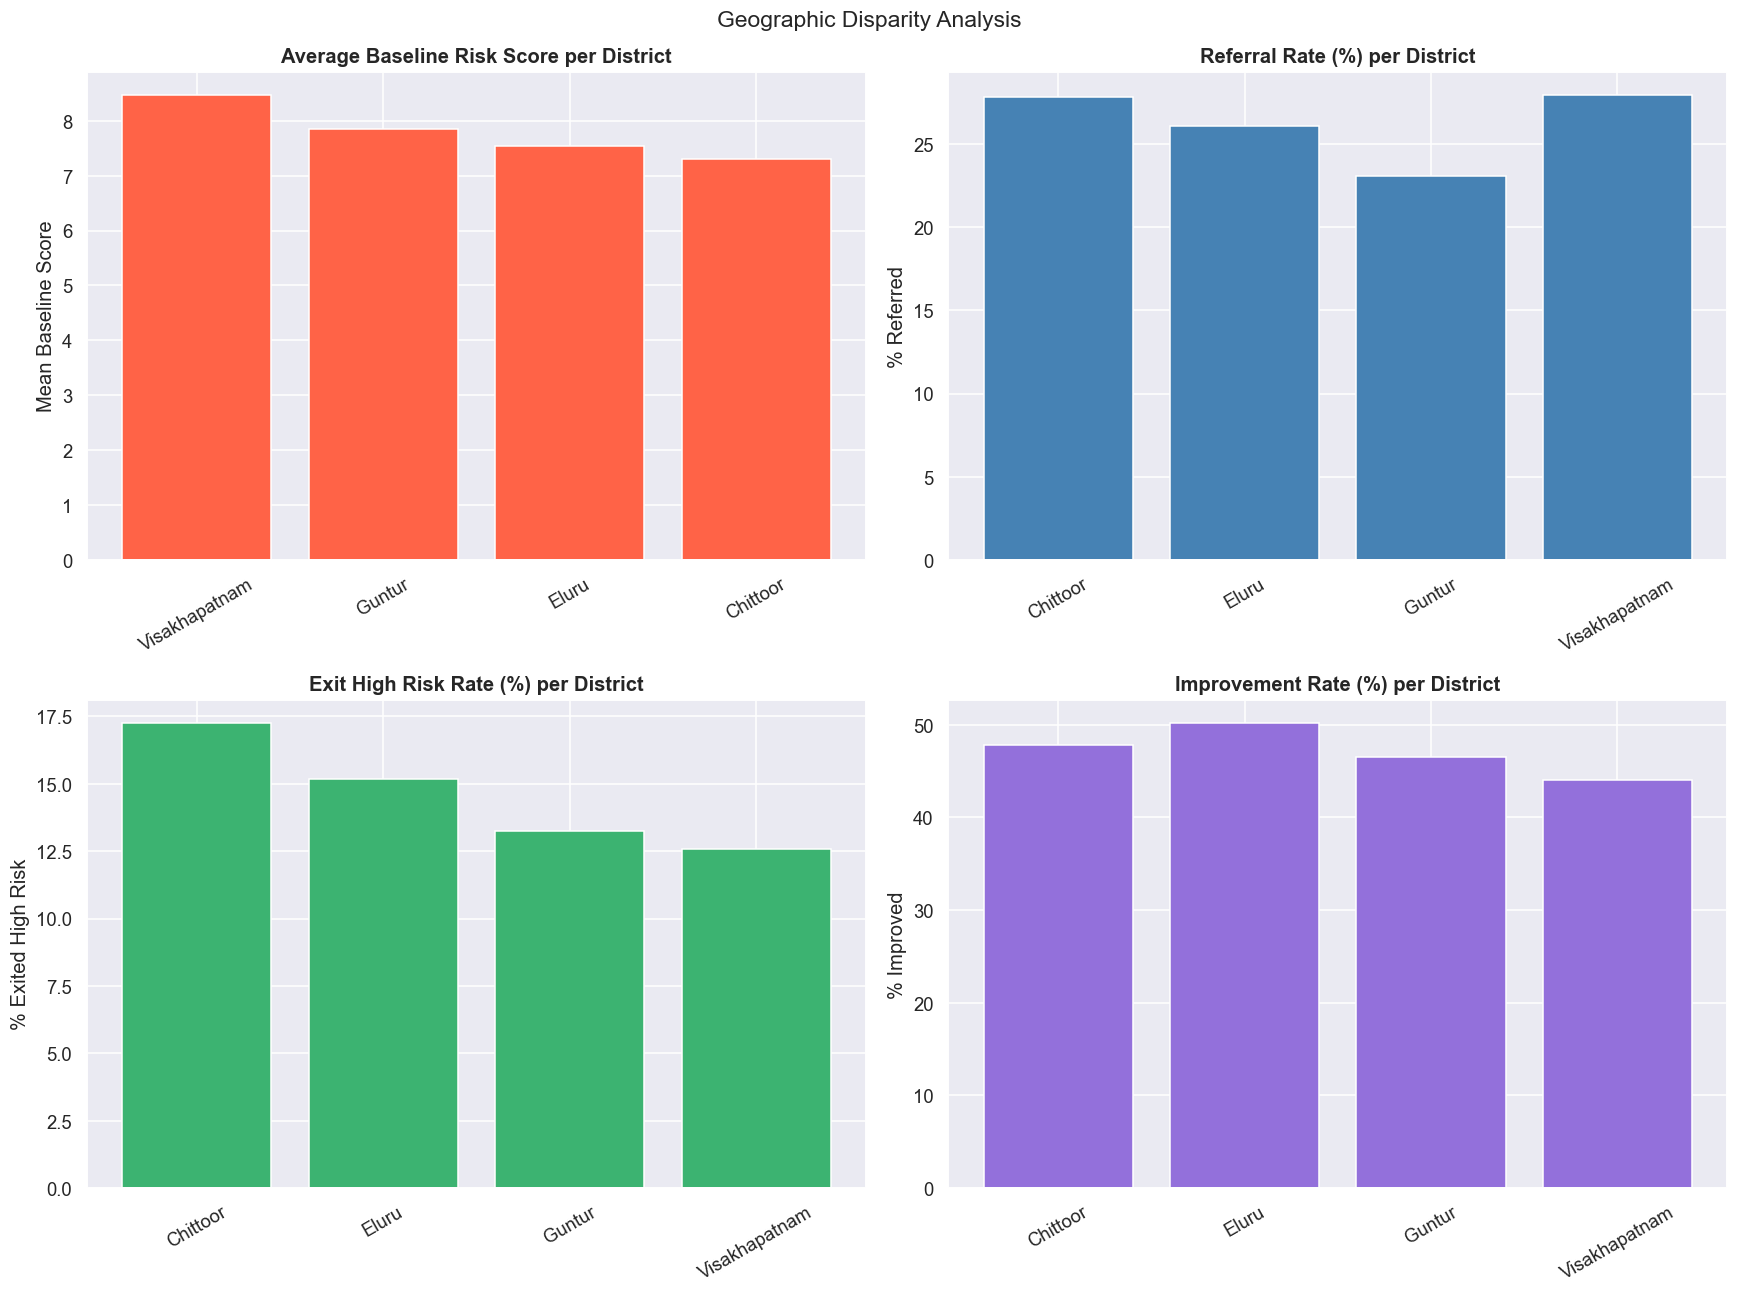

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()  # ← flatten 2D to 1D

# Average baseline score per district
dist_risk = master.groupby('district')['baseline_score'].mean().sort_values(ascending=False)
axes[0].bar(dist_risk.index, dist_risk.values, color='tomato', edgecolor='white')
axes[0].set_title('Average Baseline Risk Score per District')
axes[0].set_ylabel('Mean Baseline Score')
axes[0].tick_params(axis='x', rotation=30)

# Referral rate per district
dist_ref = master.groupby('district')['referral_triggered'].apply(
    lambda x: (x == 'Yes').mean() * 100)
dist_ref.sort_values(ascending=False)
axes[1].bar(dist_ref.index, dist_ref.values, color='steelblue', edgecolor='white')
axes[1].set_title('Referral Rate (%) per District')
axes[1].set_ylabel('% Referred')
axes[1].tick_params(axis='x', rotation=30)

# Exit high risk rate per district
dist_exit = master.groupby('district')['exit_high_risk'].apply(
    lambda x: (x == 'Yes').mean() * 100)
axes[2].bar(dist_exit.index, dist_exit.values, color='mediumseagreen', edgecolor='white')
axes[2].set_title('Exit High Risk Rate (%) per District')
axes[2].set_ylabel('% Exited High Risk')
axes[2].tick_params(axis='x', rotation=30)

# Improvement rate per district
dist_imp = master.groupby('district')['improvement_status'].apply(
    lambda x: (x == 'Improved').mean() * 100)
axes[3].bar(dist_imp.index, dist_imp.values, color='mediumpurple', edgecolor='white')
axes[3].set_title('Improvement Rate (%) per District')
axes[3].set_ylabel('% Improved')
axes[3].tick_params(axis='x', rotation=30)

plt.suptitle('Geographic Disparity Analysis', fontsize=15)
plt.tight_layout()
plt.show()

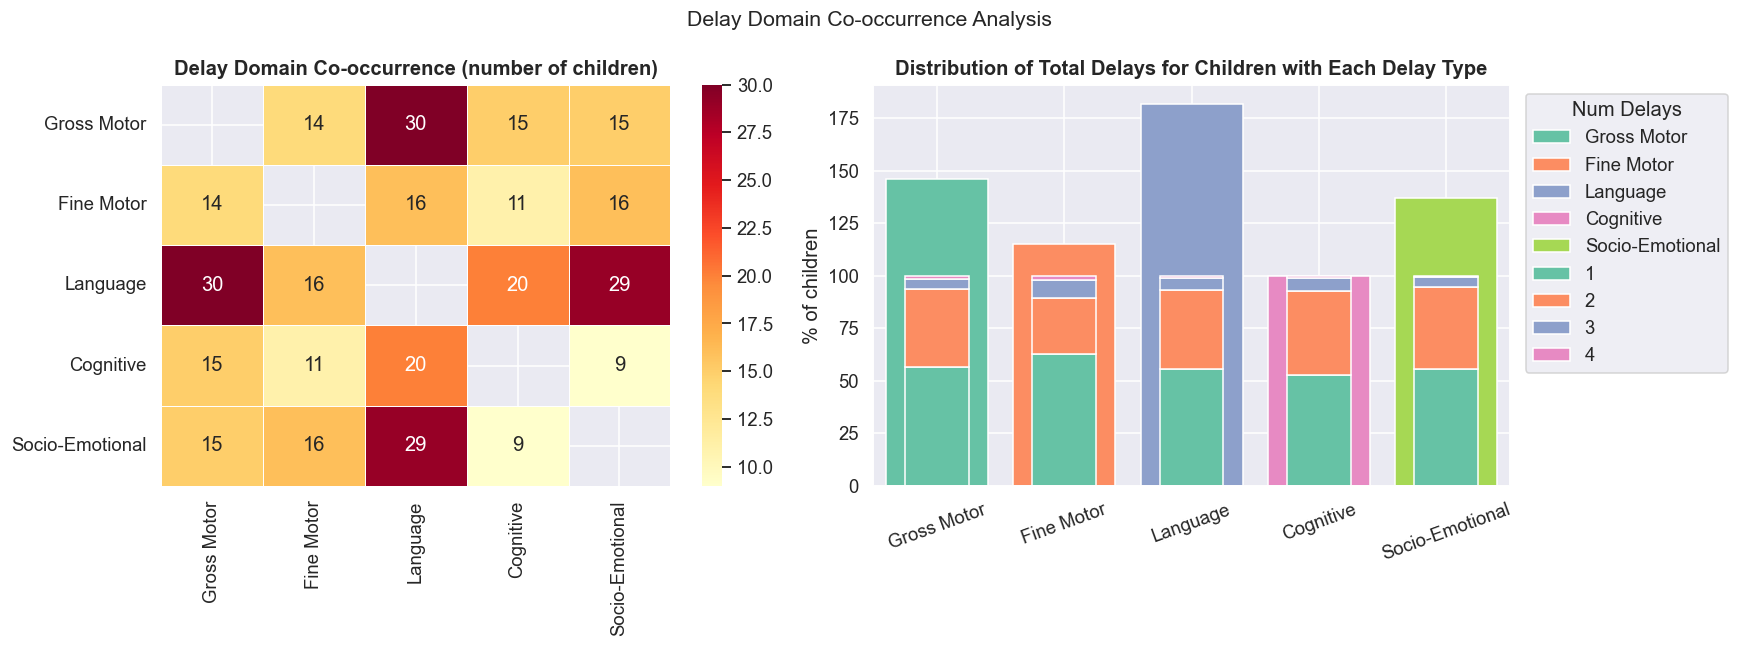

In [55]:
delay_cols = ['GM_delay','FM_delay','LC_delay','COG_delay','SE_delay']
delay_labels = ['Gross Motor','Fine Motor','Language','Cognitive','Socio-Emotional']

# Co-occurrence matrix
co_occur = master[delay_cols].T.dot(master[delay_cols])
co_occur.index = co_occur.columns = delay_labels

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
mask = np.eye(len(co_occur), dtype=bool)
sns.heatmap(co_occur, mask=mask, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=.5, ax=axes[0])
axes[0].set_title('Delay Domain Co-occurrence (number of children)')

# Stacked bar — children with each delay, broken by num_delays
delay_df = master[delay_cols + ['num_delays']].copy()
delay_df.columns = delay_labels + ['num_delays']
for label in delay_labels:
    grp = delay_df[delay_df[label] == 1]['num_delays'].value_counts().sort_index()
    axes[1].bar(delay_labels.index(label),
                grp.values[:5].sum(), label=label)

pd.DataFrame({
    label: master[master[col] == 1]['num_delays'].value_counts(normalize=True) * 100
    for col, label in zip(delay_cols, delay_labels)
}).fillna(0).T.plot(kind='bar', stacked=True, ax=axes[1],
                    edgecolor='white', rot=20)
axes[1].set_title('Distribution of Total Delays for Children with Each Delay Type')
axes[1].set_ylabel('% of children')
axes[1].legend(title='Num Delays', bbox_to_anchor=(1.01, 1))

plt.suptitle('Delay Domain Co-occurrence Analysis', fontsize=14)
plt.tight_layout()
plt.show()

In [58]:
kpis = {
    'Total Children'          : len(master),
    'High Risk %'             : f"{(master['baseline_category'] == 'High Risk').mean()*100:.1f}%",
    'Referral Rate %'         : f"{(master['referral_triggered'] == 'Yes').mean()*100:.1f}%",
    'Improvement Rate %'      : f"{(master['improvement_status'] == 'Improved').mean()*100:.1f}%",
    'Exit High Risk %'        : f"{(master['exit_high_risk'] == 'Yes').mean()*100:.1f}%",
    'Follow-up Completion %'  : f"{(master['followup_conducted'] == 'Yes').mean()*100:.1f}%",
    'Avg Baseline Score'      : f"{master['baseline_score'].mean():.1f}",
    'Avg Delay Reduction (mo)': f"{master['reduction_in_delay_months'].mean():.1f}"
}

kpi_df = pd.DataFrame(kpis.items(), columns=['KPI', 'Value'])
kpi_df.style.set_properties(**{'text-align': 'left'}).hide(axis='index')

KPI,Value
Total Children,1000
High Risk %,0.0%
Referral Rate %,26.3%
Improvement Rate %,47.2%
Exit High Risk %,14.6%
Follow-up Completion %,29.4%
Avg Baseline Score,7.8
Avg Delay Reduction (mo),2.5


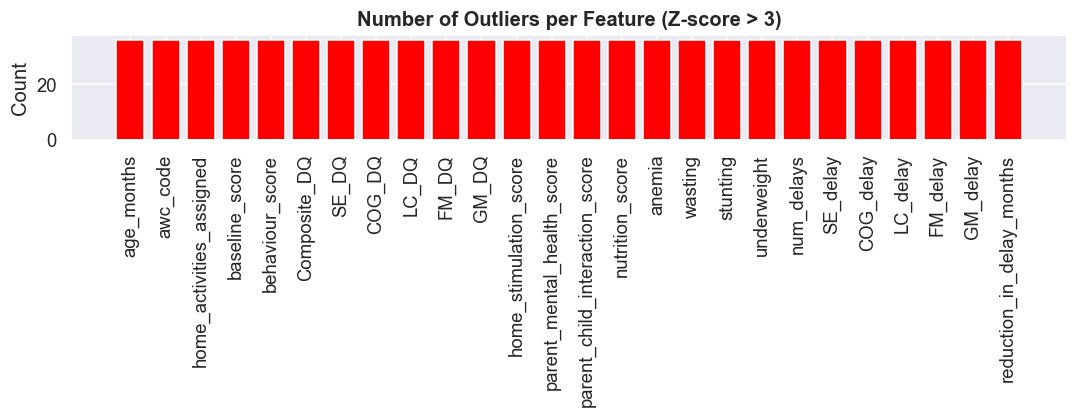

In [63]:
from scipy import stats

num_cols = master.select_dtypes(include='number').columns
z_scores = np.abs(stats.zscore(master[num_cols].fillna(master[num_cols].median())))
outliers = pd.Series((z_scores > 3).sum(), index=num_cols)
outliers = outliers[outliers > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(outliers.index, outliers.values, color='red', edgecolor='white')
ax.set_title('Number of Outliers per Feature (Z-score > 3)')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

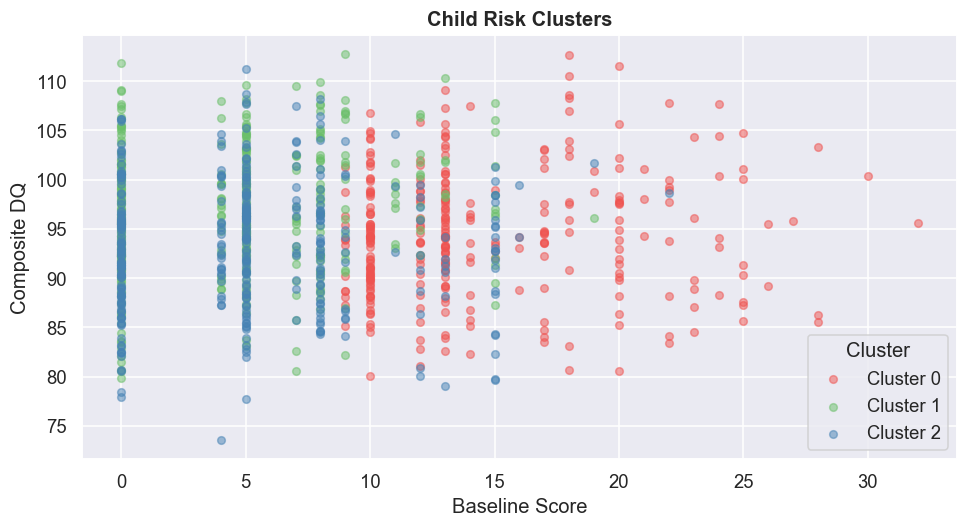


Cluster Profiles (Mean Values):
         baseline_score  num_delays  nutrition_score  Composite_DQ  behaviour_score
cluster                                                                            
0                 14.70        1.51             1.24         94.53             7.21
1                  4.65        0.34             1.41         96.62            10.43
2                  5.23        0.33             1.16         93.28             3.07


In [64]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

cluster_cols = ['baseline_score', 'num_delays', 'nutrition_score',
                'Composite_DQ', 'behaviour_score']

cluster_df = master[cluster_cols].fillna(master[cluster_cols].median())
scaler = StandardScaler()
scaled = scaler.fit_transform(cluster_df)

kmeans = KMeans(n_clusters=3, random_state=42)
master['cluster'] = kmeans.fit_predict(scaled)

# Scatter plot
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#ef5350', '#6abf69', 'steelblue']
for cluster in sorted(master['cluster'].unique()):
    grp = master[master['cluster'] == cluster]
    ax.scatter(grp['baseline_score'], grp['Composite_DQ'],
               label=f'Cluster {cluster}', alpha=0.5, s=25,
               color=colors[cluster])
ax.set_xlabel('Baseline Score')
ax.set_ylabel('Composite DQ')
ax.set_title('Child Risk Clusters')
ax.legend(title='Cluster')
plt.tight_layout()
plt.show()

# Cluster profiles
print("\nCluster Profiles (Mean Values):")
print(master.groupby('cluster')[cluster_cols].mean().round(2))